# OptiChain · Demand forecasting and stock planning on VN2

**Goal.** A retail chain sells 599 store-product combinations. Every Monday the planner orders stock from
the central warehouse; it arrives **two weeks later**. Order too little and customers leave empty-handed
(lost sales, **1 € per unit**). Order too much and stock sits on the shelf (**0.2 € per unit per week**).
This notebook builds the whole pipeline that turns three years of weekly sales into those orders, and
tests it on the eight real weeks of the **VN2 Inventory Planning Challenge** (2025).

**Data.** The VN2 competition data, organised by Nicolas Vandeput (SupChains): real weekly sales of an
anonymous retail chain, from April 2021 to June 2024, with an in-stock flag for every week, the product
and store hierarchy, and the real stock and orders in transit at the start of the competition.
Licence: CC BY 4.0. *Vandeput, N. (2025). VN2 Inventory Planning Challenge. https://supchains.com/vn2-inventory-competition/*

**The steps.** Steps 1-11 follow the classical time-series (Box-Jenkins) workflow. Steps 12-18 compare
forecasting methods and turn the forecasts into stock decisions.

| # | Step | What it produces |
|---|---|---|
| 1 | Data collection | the official files (downloaded if missing) and a data-quality audit |
| 2 | Exploratory data analysis | line graphs, scatter plots, histograms, QQ plots, descriptive statistics |
| 3 | Missing values | hidden gaps (out-of-stock weeks, weeks before launch) found and handled |
| 4 | Stationarity | ADF test, with KPSS as a cross-check |
| 5 | Transformations | log and differencing, re-tested |
| 6 | Seasonality | STL decomposition into trend + season + remainder |
| 7 | ACF and PACF | autocorrelation plots |
| 8 | Model identification | AR, MA, ARMA, ARIMA or SARIMA? |
| 9 | Lags | which past weeks matter |
| 10 | AIC and BIC | the best model order, for the network and for each of the 599 series |
| 11 | Residual diagnostics | Ljung-Box (white noise?), Jarque-Bera, ARCH-LM, then **GARCH** |
| 12 | Forecasting models | 10 methods, from "last week" to ARIMA and a global LightGBM |
| 13 | Backtest | accuracy on 30 past weeks, and Ljung-Box on the forecast errors |
| 14 | Uncertainty | spread of demand around each forecast, calibration check |
| 15 | Inventory simulator | the official rules, verified against the official benchmark score |
| 16 | Ordering policy | Monte Carlo newsvendor, tuned on the past by simulation |
| 17 | Final test | the 8 competition weeks, scored like the competition |
| 18 | Stock outlook | the next order and the stockout risk after the data ends |
| 19-20 | Save and conclude | artefacts for the dashboard (`streamlit run app/Home.py`) |

Every number in the dashboard comes from this notebook. Run it top to bottom (about 20 minutes).

## 0 · Setup

In [1]:
import json
import warnings

import numpy as np
import pandas as pd

from optichain import data as D            # loading and cleaning the VN2 files
from optichain import evaluation as E      # backtest and error measures
from optichain import inventory as I       # the official simulator and the ordering rule
from optichain import models as M          # the forecasting models
from optichain import planning as P        # round-by-round forecasts and the stock plan
from optichain import plots                # the charts
from optichain import timeseries as TS     # the Box-Jenkins tools (ADF, STL, ARIMA, GARCH, ...)
from optichain.config import load_config

cfg = load_config()                        # all settings come from config.yaml
ART = cfg.paths.artifacts_dir              # results are saved here for the dashboard
ART.mkdir(parents=True, exist_ok=True)
SEED = cfg.seed                            # same seed = same numbers on every run
warnings.filterwarnings("ignore")          # hide statsmodels' convergence messages; fits are checked below
plots.style()

## 1 · Data collection

### 1.1 Load the files

The organiser published the files on GitHub ([SupChains/VN2](https://github.com/SupChains/VN2)). The
helper below downloads any file that is missing into `data/raw/vn2/`, so the notebook runs on a fresh
machine.

| File | Content |
|---|---|
| `Week 0 - 2024-04-08 - Sales.csv` | weekly units sold, 157 weeks of history: what planners knew before round 1 |
| `Week 1 … Week 8 - Sales.csv` | the same table, one more week each round; **Week 8 holds every week** |
| `Week 0 - In Stock.csv` | `True` when stock was left at the end of the week |
| `Week 0 - Master.csv` | product and store hierarchy (anonymised codes) |
| `Week 0 - … - Initial State.csv` | stock on the shelf and orders in transit at the end of week 0 |

In [2]:
fetched = D.download_vn2(cfg.paths.raw_dir, cfg.paths.source_url)   # downloads only the files that are missing
print("Downloaded:", fetched or "nothing, every file is already here")

Downloaded: nothing, every file is already here


In [3]:
panel = D.load_panel(cfg.paths.raw_dir, cfg.competition.week_0)    # sales, in-stock flags, groups, starting stock
hist = M.History.from_panel(panel)                                  # the same data as arrays, for the models
t0 = panel.t0                                                       # column of week 0 (8 April 2024)
print(f"{panel.sales.shape[0]} store-products x {panel.sales.shape[1]} weeks")
panel.sales.iloc[:5, :8]

599 store-products x 165 weeks


2021-04-12  2021-04-19  2021-04-26  2021-05-03  2021-05-10  2021-05-17  2021-05-24  2021-05-31
Store Product                                                                                                
0     126            0.00        0.00        3.00        3.00        0.00        1.00        1.00        0.00
      182            0.00        0.00        0.00        0.00        0.00        0.00        0.00        0.00
1     124           13.00        4.00       10.00        5.00        1.00        2.00        3.00        4.00
2     124            5.00        5.00       12.00       16.00       10.00        8.00       10.00        9.00
      126            0.00        0.00        6.00        5.00        7.00        4.00        1.00        2.00

Each row is one product in one store; each column one week (its Monday). The in-stock flags have the same shape:

In [4]:
display(panel.in_stock.iloc[:5, :8])    # True = stock was left at the end of the week
display(panel.master.head())            # product and store groups
panel.initial.head()                    # stock on the shelf and on its way at the start

2021-04-12  2021-04-19  2021-04-26  2021-05-03  2021-05-10  2021-05-17  2021-05-24  2021-05-31
Store Product                                                                                                
0     126            True        True        True        True        True        True        True        True
      182           False       False       False       False       False       False       False       False
1     124            True        True        True        True        True        True        True        True
2     124            True        True        True        True        True        True        True        True
      126           False       False        True        True        True        True        True        True

ProductGroup  Division  Department  DepartmentGroup  StoreFormat  Format
Store Product                                                                          
0     126            301202      3012          30               11            1      13
      182            440403      4404          44               11            1      13
1     124            240201      2402          24               11            1      13
2     124            240201      2402          24               11            1      13
      126            301202      3012          30               11            1      13

Start Inventory  Sales  Missed Sales  End Inventory  In Transit W+1  In Transit W+2  Holding Cost  Shortage Cost  Cumulative Holding Cost  \
Store Product                                                                                                                                              
0     126                    0      0             0              3               0               3             0              0                        0   
      182                    0      0             0              1               0               1             0              0                        0   
1     124                    0      0             0              6               0               6             0              0                        0   
2     124                    0      0             0              9               0               7             0              0                        0   
      126                    0      0             0              3               0               1             0              0                        0   

               Cumulative Shortage Cost  
Store Product                            
0     126                             0  
      182                             0  
1     124                             0  
2     124                             0  
      126                             0

### 1.2 Audit (data quality)

Before modelling: is the data complete and sane? We check gaps, negative or fractional sales, and that the
nine weekly sales files agree with each other (each must be the previous one plus one week).

In [5]:
audit = D.audit(panel)
audit

,value
fact,
Store-product rows,599
Stores,67
Products,297
Weeks in total,165
History weeks (to week 0),157
Competition weeks (1-8),8
First week,2021-04-12
Last week,2024-06-03
Missing values,0


In [6]:
print(D.check_weekly_files(cfg.paths.raw_dir, panel))

All 9 sales files are consistent: same rows, same history, one extra week each.


**Reading the audit.** The data is complete (no missing values, no negatives, whole units). Two facts
matter for everything that follows:

* **About 43% of weeks have zero sales.** Many items sell a handful of units a week; the models must
  handle slow, intermittent demand.
* **About 1 week in 10 is flagged out of stock** (part of them before the product was even launched).
  In those weeks the shelf was empty, so the recorded sales say nothing reliable about demand.
  Treating them as demand would teach the models to under-forecast.

## 2 · Exploratory data analysis

First a long version of the data (one row per store-product-week, hierarchy attached), easier for plots
and tables. The models keep the wide matrix.

In [7]:
long = D.to_long(panel)                            # one row per store-product-week
hist_cols = panel.sales.columns <= panel.week0     # the 157 history weeks; the 8 test weeks stay unseen
long.head()

,Store,Product,week,sales,in_stock,launched,demand,phase,ProductGroup,Division,Department,DepartmentGroup,StoreFormat,Format
0,0,126,2021-04-12,0.00,True,False,NaN,history,301202,3012,30,11,1,13
1,0,126,2021-04-19,0.00,True,False,NaN,history,301202,3012,30,11,1,13
2,0,126,2021-04-26,3.00,True,True,3.00,history,301202,3012,30,11,1,13
3,0,126,2021-05-03,3.00,True,True,3.00,history,301202,3012,30,11,1,13
4,0,126,2021-05-10,0.00,True,True,0.00,history,301202,3012,30,11,1,13


### 2.1 Line graph: the network over time

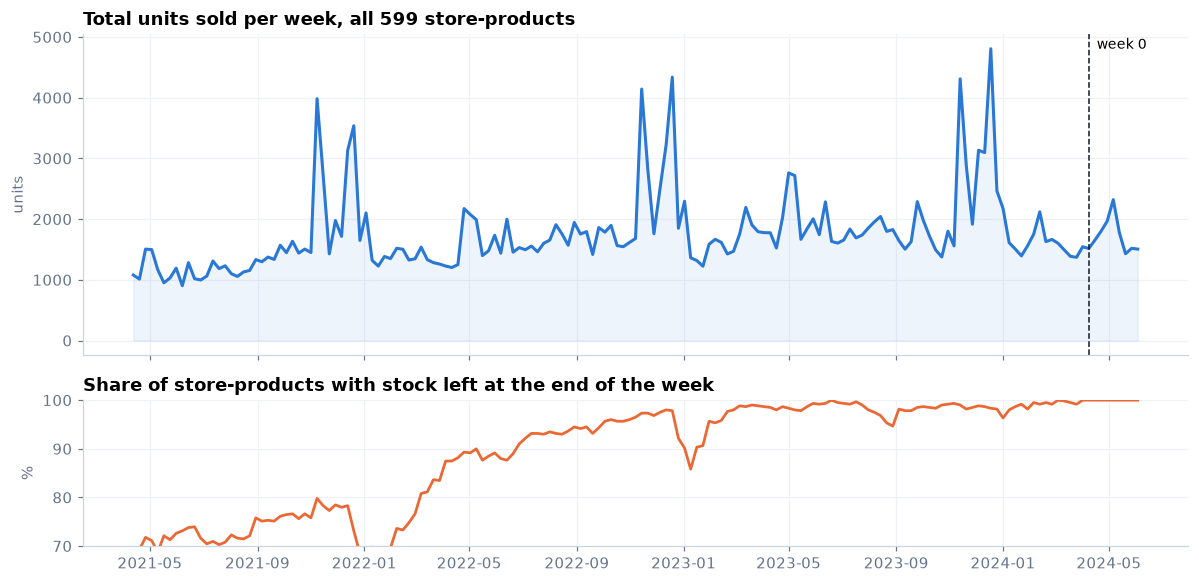

Average week: 1,761 units


In [8]:
total = panel.sales.sum(axis=0)                    # units sold by all store-products, per week
instock_share = panel.in_stock.mean(axis=0)        # share of store-products with stock left, per week
plots.network_over_time(total, instock_share, panel.week0)
print(f"Average week: {total.mean():,.0f} units")

Sales are fairly stable with a clear yearly rhythm. Availability is not: in some periods 15-20% of rows
ended the week with an empty shelf. This is why the in-stock flag matters so much.

### 2.2 Line graph of the seasonal profile

The benchmark's seasonality: mean sales of all rows in each calendar week (ISO week number), divided by
the overall mean. A factor of 1.2 means that week usually sells 20% more than an average week.

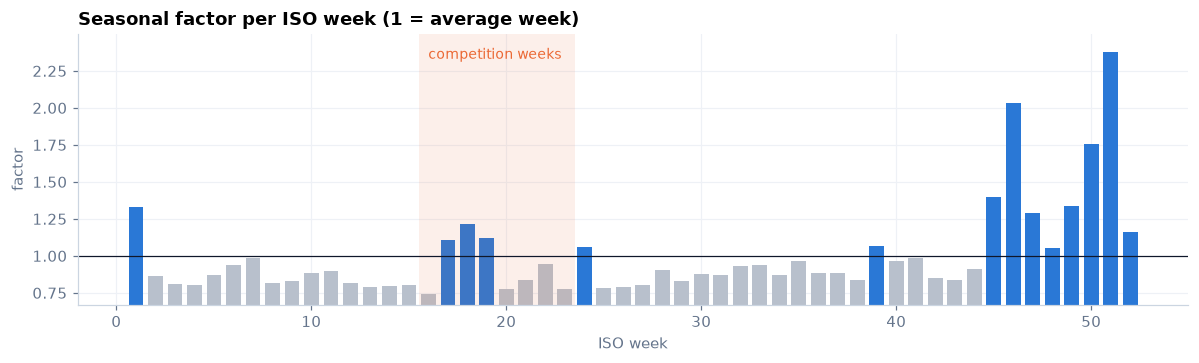

In [9]:
season = M.season_factors(hist.upto(t0))           # average sales of each ISO week / average week
plots.seasonal_factors(season)

### 2.3 Histograms: how much does a store-product sell?

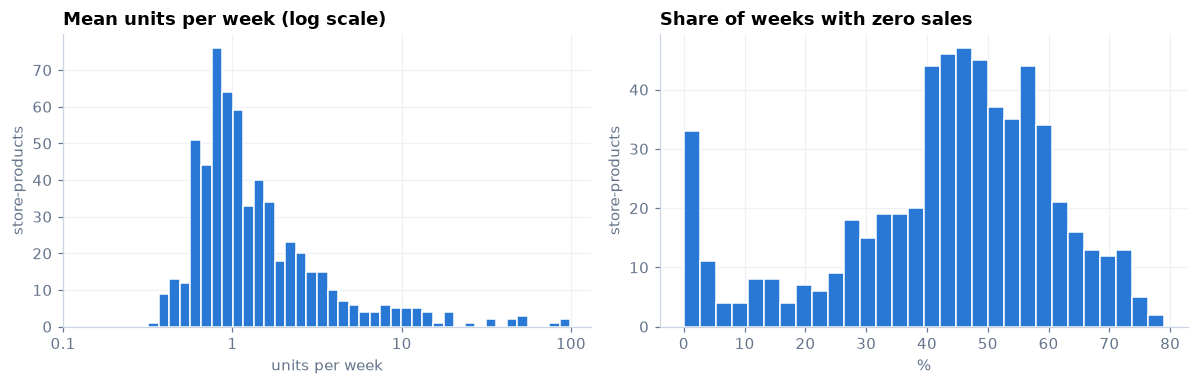

Median store-product: 1.1 units/week; 75% sell under 2 a week


In [10]:
sales_h = panel.sales.loc[:, hist_cols]            # history weeks only
mean_week = sales_h.mean(axis=1)                   # average units per week, per store-product
zero_share = (sales_h == 0).mean(axis=1)           # share of weeks with no sale
plots.sales_histograms(mean_week, zero_share)
print(f"Median store-product: {mean_week.median():.1f} units/week; {(mean_week < 2).mean():.0%} sell under 2 a week")

Demand is extremely skewed: most rows sell a few units a week, a few sell hundreds. Error metrics in
units will be dominated by the big sellers; that is fine here, because costs are in units too.

### 2.4 Pareto: where the volume is

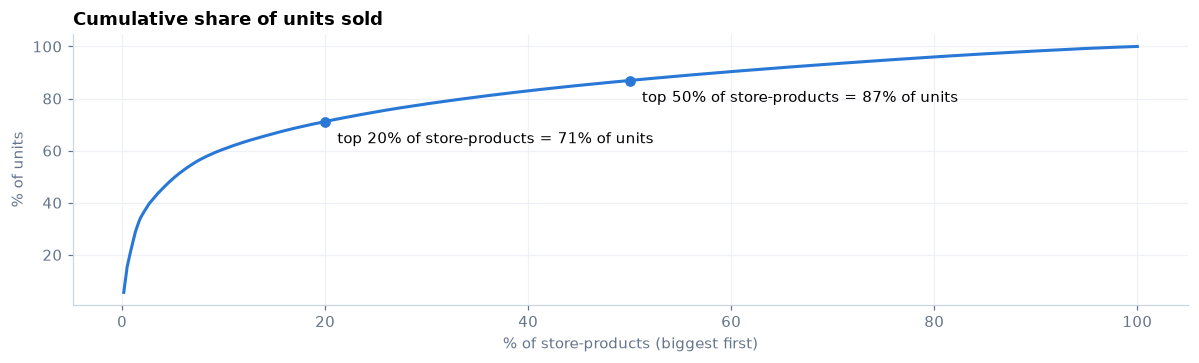

In [11]:
volume = sales_h.sum(axis=1).sort_values(ascending=False)    # total units per store-product, biggest first
plots.pareto(volume.cumsum() / volume.sum())

### 2.5 Scatter plots

Left: each store-product's average weekly sales against its variability (coefficient of variation).
Right: the network total this week against last week (a *lag plot*). A tight diagonal cloud means this
week's sales are strongly related to last week's, which is what autoregressive models exploit.

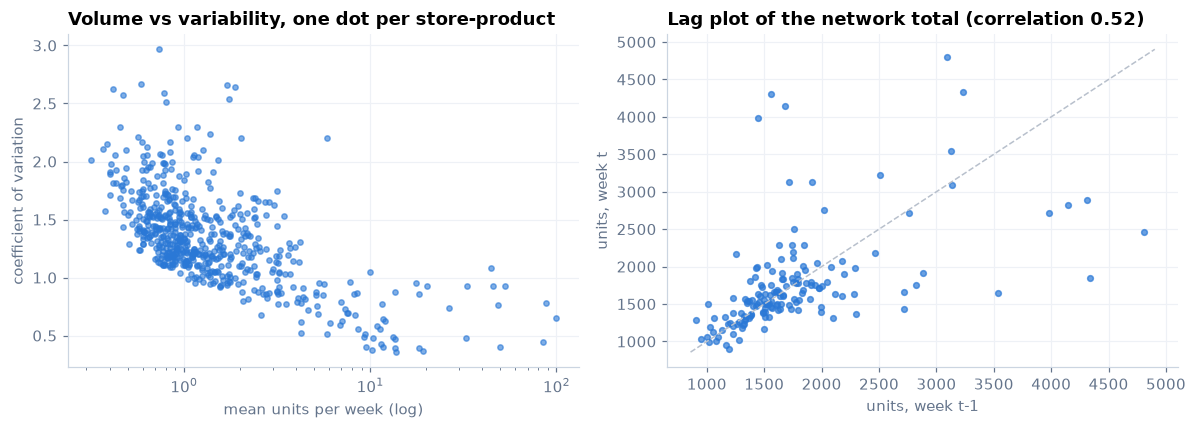

In [12]:
total_h = total.loc[:panel.week0].to_numpy()                 # network total, history weeks
cv = sales_h.std(axis=1) / mean_week                         # coefficient of variation per store-product
plots.scatter_plots(mean_week, cv, total_h)

Slow sellers are the most variable (top left), a classic pattern for count data. The lag plot shows strong
week-to-week dependence in the total, so an autoregressive term will be useful.

### 2.6 QQ plots: are the sales normally distributed?

A QQ plot compares the quantiles of the data with those of a normal distribution: points on the line mean
"normal". ARIMA forecasts do not need normal data, but their textbook prediction intervals assume normal
errors.

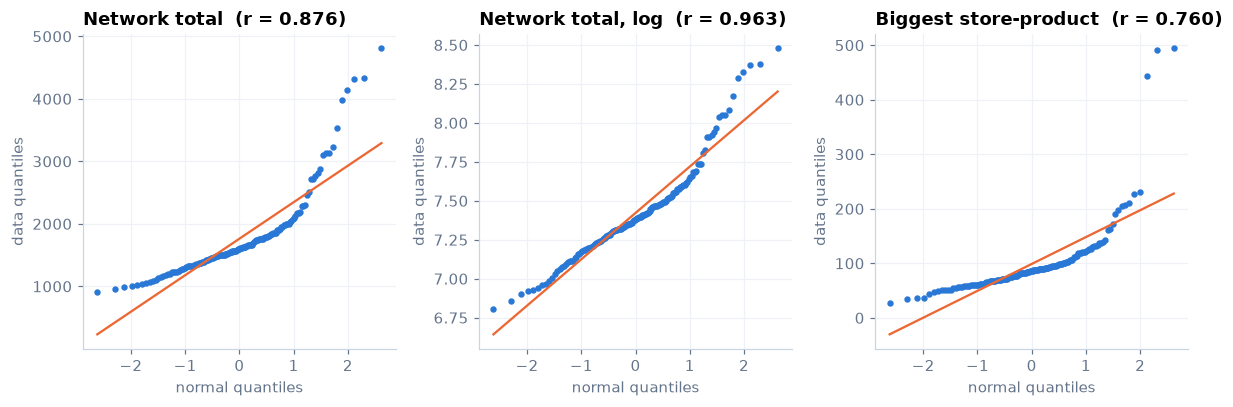

In [13]:
biggest = int(sales_h.sum(axis=1).to_numpy().argmax())       # the store-product with the most sales
plots.qq_plots({"Network total": total_h, "Network total, log": np.log(total_h),
                "Biggest store-product": sales_h.iloc[biggest].to_numpy()})

The total is close to normal in the middle but has a heavy upper tail (a few very strong weeks: the
year-end peak). The log makes it more symmetric. Single store-products are far from normal: they are small
counts.

### 2.7 Descriptive statistics

In [14]:
desc = TS.describe({"Network total": total_h, "Biggest store-product": sales_h.iloc[biggest].to_numpy(),
                    "Median of all store-products": sales_h.median(axis=0).to_numpy()})
display(desc.T.round(2))
per_row = TS.describe({i: sales_h.iloc[i].to_numpy() for i in range(hist.n)})   # the same for each store-product
per_row[["mean", "CV", "skewness", "excess kurtosis", "zero weeks %"]].astype(float).describe().round(2)

,Network total,Biggest store-product,Median of all store-products
weeks,157.00,157.00,157.00
mean,"1,762.09",98.84,0.82
std,659.48,64.18,0.66
min,903.00,28.00,0.00
25%,"1,387.00",68.00,0.00
median,"1,605.00",86.00,1.00
75%,"1,861.00",103.00,1.00
max,"4,806.00",494.00,4.00
CV,0.37,0.65,0.81
skewness,2.27,4.15,0.89


,mean,CV,skewness,excess kurtosis,zero weeks %
count,599.00,599.00,599.00,599.00,599.00
mean,2.94,1.34,2.08,7.25,43.19
std,8.23,0.40,1.10,9.70,18.17
min,0.32,0.36,0.25,-0.27,0.00
25%,0.78,1.11,1.36,1.89,35.03
50%,1.08,1.31,1.78,3.90,46.50
75%,2.01,1.54,2.50,8.61,55.41
max,98.84,2.97,8.15,82.28,78.98


**Reading.** The total sells about 1,800 units a week with moderate spread. The typical store-product sells
about 1 unit a week, has many zero weeks, and is strongly right-skewed (skewness above 1) with heavy tails
(positive excess kurtosis). Jarque-Bera rejects normality almost everywhere.

### 2.8 Stockouts and hierarchy

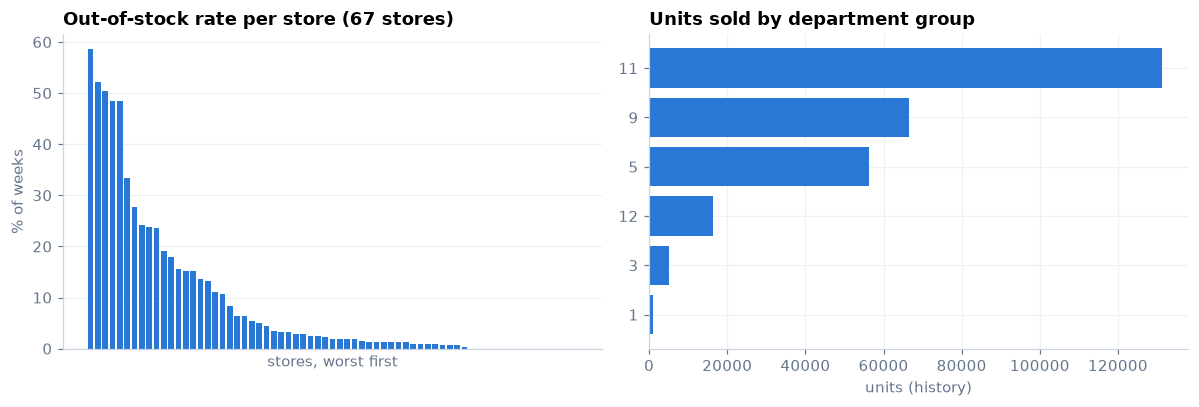

Out-of-stock rate per store: from 0% to 59%


In [15]:
oos = 1 - panel.in_stock.loc[:, hist_cols].mean(axis=1)                       # out-of-stock rate per store-product
store_oos = oos.groupby(level="Store").mean().sort_values(ascending=False)     # ... per store
dept_sales = long[long.phase == "history"].groupby("DepartmentGroup")["sales"].sum().sort_values()
plots.stockouts_and_groups(store_oos, dept_sales)
print(f"Out-of-stock rate per store: from {store_oos.min():.0%} to {store_oos.max():.0%}")

**What the EDA tells us**

1. Demand is mostly slow and intermittent → include Croston and TSB, and use a count distribution
   (negative binomial) for uncertainty rather than a normal one.
2. There is a yearly seasonal pattern shared across the network → deseasonalise with network factors
   (individual rows are too noisy to estimate their own).
3. Censoring is frequent and biased → every model learns from clean weeks only.
4. Rows share structure (stores, departments) → a single *global* machine-learning model across all rows
   can borrow strength from similar rows.

## 3 · Dealing with missing values

The audit found **no missing cells**: every store-product has a number for every week. But two kinds of
weeks are *hidden* missing values, because the number recorded is not a measurement of demand.

### 3.1 Before launch: leading zeros are not demand

Some products appear in the data before they were on sale: their first weeks are zeros because the
product did not exist yet in that store, not because nobody wanted it. We treat every week before the
first sale as *not launched* and leave it out of the demand history.

Selling from the first week: 38% · launched later: 371


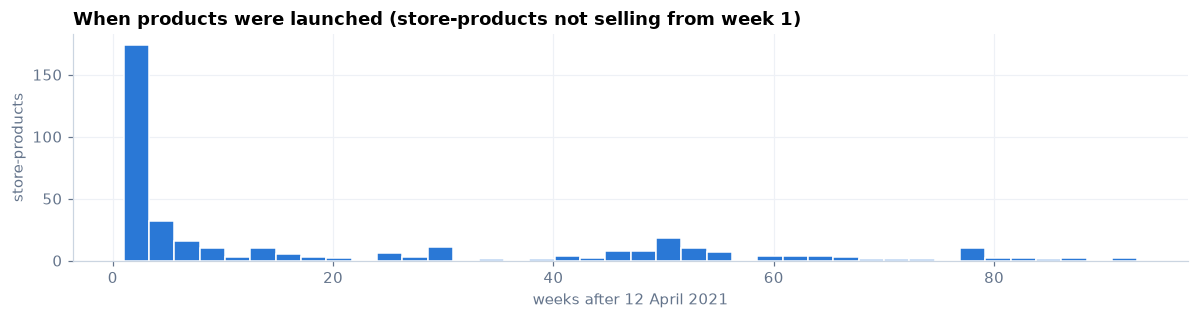

In [16]:
launched = D.launch_mask(panel.sales)                     # True from the first week with a sale
first_sale = launched.to_numpy().argmax(axis=1)           # week number of the first sale
print(f"Selling from the first week: {(first_sale == 0).mean():.0%} · launched later: {(first_sale > 0).sum()}")
plots.launch_histogram(first_sale)

### 3.2 Out-of-stock weeks: censored demand

The key preprocessing step. When a week ends with an empty shelf, its sales are a *lower bound* on
demand: some customers found nothing. We call these weeks **censored** and set them aside (`NaN`) in the
demand history. Models then learn from weeks where sales = demand.

How biased are censored weeks? Compare what was sold in out-of-stock weeks with normal weeks:

In [17]:
demand = D.clean_demand(panel.sales, panel.in_stock)      # out-of-stock and pre-launch weeks become NaN (missing)

in_stock_h, launched_h = panel.in_stock.loc[:, hist_cols], launched.loc[:, hist_cols]
censored = ~in_stock_h & launched_h                       # out-of-stock weeks after launch
print(f"Weeks set aside as censored: {censored.to_numpy().mean():.1%}")
print(f"Out-of-stock weeks with zero sales: {(sales_h[censored].stack().dropna() == 0).mean():.0%}")

Weeks set aside as censored: 4.3%
Out-of-stock weeks with zero sales: 100%


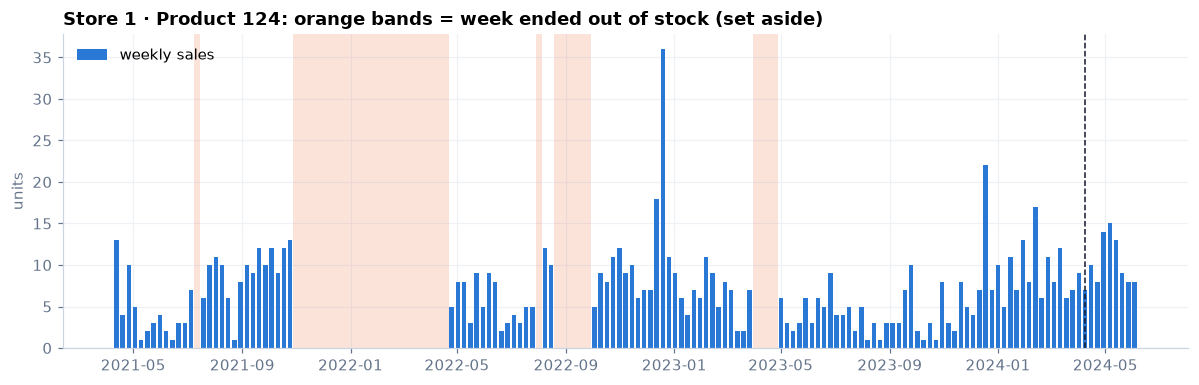

In [18]:
oos_rate = (~in_stock_h).mean(axis=1)
example = oos_rate[(oos_rate > 0.2) & (mean_week > 3)].index[0]    # a busy store-product that often ran out
plots.stockout_example(panel.sales.loc[example], panel.in_stock.loc[example], panel.week0,
                       f"Store {example[0]} · Product {example[1]}")

In this data an out-of-stock flag means the shelf was empty for the whole week: **every** flagged week
recorded zero sales. These zeros are about supply, not demand. Left in, they would drag every average
towards zero; setting them aside costs some data but removes that systematic downward bias.

### 3.3 How each method handles the gaps

| Method | Treatment of a missing week |
|---|---|
| Moving averages, smoothing, Croston, TSB | skip it (the averages use the clean weeks only) |
| ARIMA / SARIMA | kept as missing: the state-space (Kalman filter) estimation skips it exactly |
| ADF, KPSS, STL, ACF (need an unbroken series) | linear interpolation between the neighbouring clean weeks |
| LightGBM | never used as a training target; lag features may be missing (trees handle it) |

We do **not** fill out-of-stock weeks with zeros or a guess for the models that can skip them: an invented
value would look like real information.

### 3.4 Demand patterns (Syntetos-Boylan)

Two numbers summarise how a row sells, on its clean history:

* **ADI**, the average number of weeks between two sales (1 = sells every week);
* **CV²**, how much the size of a sale varies (0 = always the same quantity).

With the standard cut-offs (ADI 1.32, CV² 0.49) every row falls into one of four patterns. They guide
model choice: Croston-type models were designed for the *intermittent* and *lumpy* ones.

pattern
intermittent    284
lumpy           175
smooth           88
erratic          52
Name: count, dtype: int64

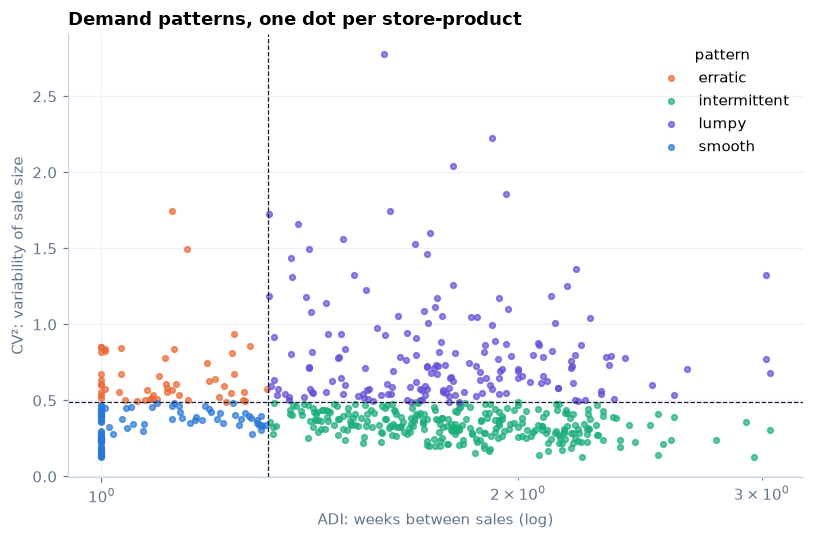

In [19]:
classes = D.classify_demand(demand.loc[:, hist_cols])     # ADI, CV² and pattern per store-product
display(classes["pattern"].value_counts())
plots.pattern_map(classes, D.ADI_CUT, D.CV2_CUT)

### 3.5 Time split: no peeking at the future

Everything is evaluated as if it were happening live. The 165 weeks are used like this:

| Window | Weeks | Used for |
|---|---|---|
| Training history | up to each forecast origin | fitting models (they never see later weeks) |
| Backtest origins 1-12 | 33 to 22 weeks before week 0 | measuring forecast-error spread (step 14) |
| Backtest origins 13-30 | 21 to 3 weeks before week 0 | accuracy (step 13) and **tuning the ordering policy** by simulation (step 16) |
| Competition weeks 1-8 | 15 Apr - 3 Jun 2024 | **final test only**: nothing is tuned on them |

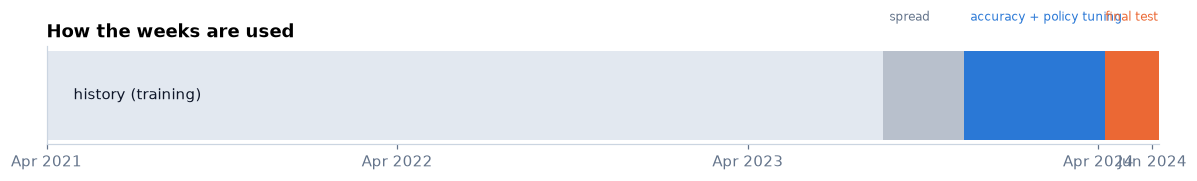

In [20]:
origins = list(range(t0 - 3 - cfg.forecast.backtest_origins + 1, t0 - 2))   # 30 past forecast dates
disp_origins = origins[:cfg.forecast.dispersion_origins]                    # first 12: error spread only
tune_origins = origins[cfg.forecast.dispersion_origins:]                    # last 18: accuracy and policy tuning
plots.time_split(panel.sales.shape[1], t0, disp_origins, tune_origins, panel.dates)

## 4 · Stationarity: the ADF test

ARMA models assume a **stationary** series: its mean and variance do not drift over time. The
**Augmented Dickey-Fuller (ADF)** test checks for a *unit root* (a random-walk-like drift):

* H0: the series has a unit root, so it is **not stationary**. A p-value below 0.05 rejects H0: stationary.

The **KPSS** test is the mirror image (H0: stationary), so using both guards against a wrong conclusion.

We walk through the Box-Jenkins steps on two series:
1. **the network total**: all 599 store-products added up (a smooth, well-behaved series);
2. **one representative store-product**: a high-volume item, on sale from the first week, rarely out of stock.

Steps 10-11 then apply the same procedure automatically to **every** store-product.

In [21]:
# The representative store-product: biggest seller among those sold from week 1, rarely out of stock, steady pattern
steady = (first_sale == 0) & (oos_rate.to_numpy() < .05) & (classes["pattern"].to_numpy() == "smooth")
ts_row = int(np.flatnonzero(steady)[sales_h[steady].sum(axis=1).to_numpy().argmax()])
ts_name = f"Store {panel.index[ts_row][0]} · Product {panel.index[ts_row][1]}"

y_net = total_h                                            # series 1: the network total
y_row = demand.iloc[ts_row, :t0 + 1].to_numpy()            # series 2: clean demand of one store-product
y_row_filled = TS.fill_gaps(y_row)                         # gaps filled, for the tests that need an unbroken series
dates_h = panel.dates[:t0 + 1]
print("Representative store-product:", ts_name)
TS.stationarity({"Network total": y_net, ts_name: y_row_filled})

Representative store-product: Store 61 · Product 124


,ADF statistic,ADF p-value,ADF lags used,ADF 5% critical,ADF says,KPSS statistic,KPSS p-value,KPSS says,verdict
Network total,-3.56,0.01,5,-2.88,stationary,0.60,0.02,not stationary,borderline (tests disagree)
Store 61 · Product 124,-3.74,0.00,4,-2.88,stationary,0.07,0.10,stationary,stationary


In [22]:
adf_all = TS.adf_all_rows(demand.loc[:, hist_cols])        # ADF p-value of every store-product
print(f"ADF on {len(adf_all)} store-products: {np.mean(adf_all < .05):.0%} stationary")

ADF on 599 store-products: 94% stationary


ADF rejects the unit root for both series. KPSS is less sure about the levels (it reacts to the strong
year-end season and the slow trend), which is why the next step tries transformations.

## 5 · Transformations

The standard fixes for non-stationarity are a **log** (stabilises a variance that grows with the level), a
**first difference** y(t) − y(t−1) (removes a drifting level) and a **seasonal difference**
y(t) − y(t−52) (removes a repeating yearly pattern). Each one is re-tested:

,ADF p-value,ADF says,KPSS p-value,KPSS says,verdict
original,0.01,stationary,0.02,not stationary,borderline (tests disagree)
log(1+y),0.00,stationary,0.01,not stationary,borderline (tests disagree)
1st difference,0.00,stationary,0.10,stationary,stationary
"log, 1st difference",0.00,stationary,0.10,stationary,stationary
seasonal difference (52),0.00,stationary,0.01,not stationary,borderline (tests disagree)


Differencing chosen: network total d = 0, Store 61 · Product 124 d = 0


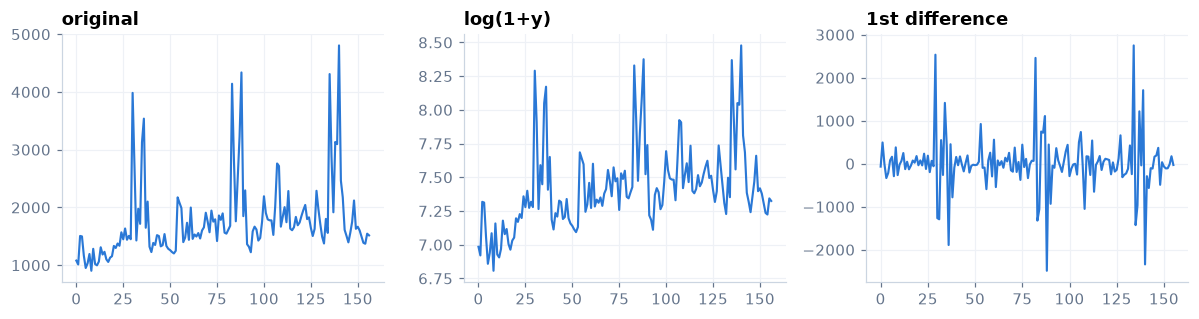

In [23]:
tr = TS.transformations(y_net, 52)                         # original, log, 1st difference, seasonal difference
tr_tab = TS.stationarity(tr)
display(tr_tab[["ADF p-value", "ADF says", "KPSS p-value", "KPSS says", "verdict"]])
d_net, d_row = TS.choose_d(y_net), TS.choose_d(y_row_filled)   # difference only while ADF finds a unit root
print(f"Differencing chosen: network total d = {d_net}, {ts_name} d = {d_row}")
plots.transformations(tr)

The first difference is stationary by both tests. The ADF rule ("difference only while ADF cannot reject a
unit root") keeps the levels (d = 0) because ADF already rejects there. Step 10 also fits d = 1 models,
so AIC double-checks this choice. The log barely changes the picture, so we keep the original units
(forecasts in units are what the stock policy needs).

## 6 · Seasonality: STL decomposition

STL (Seasonal-Trend decomposition using LOESS) splits the series into **trend + seasonal + remainder**
with a 52-week season. The *strength* of each part (0 = none, 1 = dominant) is
1 − Var(remainder) / Var(part + remainder).

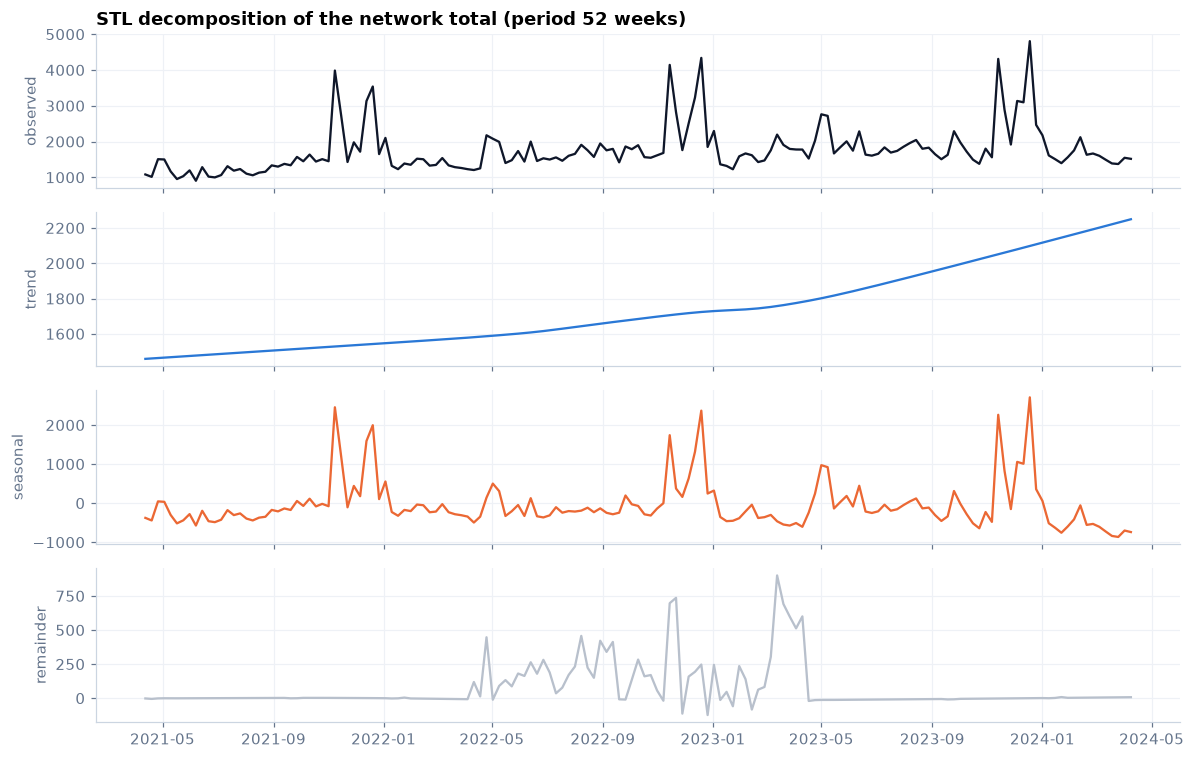

,trend strength,seasonal strength
Network total,0.61,0.93
Store 61 · Product 124,0.13,0.94


In [24]:
dec = TS.decompose(y_net, dates_h, 52)                     # trend + seasonal + remainder
plots.decomposition(dec)
s_net = TS.strength(dec)
s_row = TS.strength(TS.decompose(y_row_filled, dates_h, 52))
pd.DataFrame({"Network total": s_net, ts_name: s_row}).T.round(2)

The network total is **strongly seasonal** (the year-end peak dominates) with a moderate trend. This
high-volume store-product shares the same yearly rhythm, but its trend is weak. For the many small sellers
(one or two units a week) the season is buried in noise and two to three years are too few to estimate it
reliably per item. This is why the forecasting models take the season from the whole network (seasonal
factors) rather than from each store-product alone.

## 7 · ACF and PACF

* **ACF** (autocorrelation): correlation between the series and itself k weeks earlier.
* **PACF** (partial autocorrelation): the same, after removing the effect of the weeks in between.

Blue bars, outside the orange band (±1.96/√n), are significant at 5%.

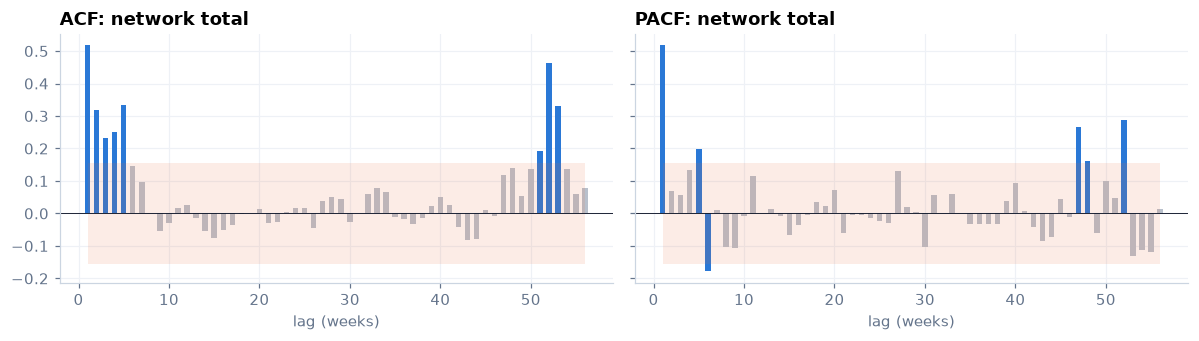

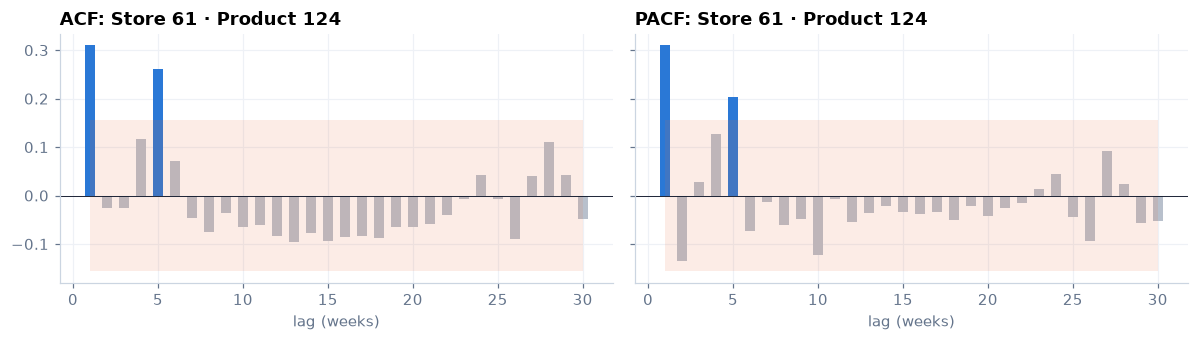

In [25]:
ap_net = TS.acf_pacf(y_net, 56)                            # d = 0, so the series is used as it is
ap_row = TS.acf_pacf(y_row_filled, 30)
plots.acf_pacf(ap_net, "network total")
plots.acf_pacf(ap_row, ts_name)

## 8 · Identify the model: AR, MA, ARMA, ARIMA or SARIMA?

The Box-Jenkins reading of the plots:

| ACF | PACF | Model |
|---|---|---|
| decays slowly | cuts off after lag p | **AR(p)** |
| cuts off after lag q | decays slowly | **MA(q)** |
| decays | decays | **ARMA(p, q)** |
| needed differencing (d > 0) | | **ARIMA(p, d, q)** |
| spike at the seasonal lag (52) | | **SARIMA(p, d, q)(P, D, Q)[52]** |
| nothing significant | nothing significant | white noise |

In [26]:
id_net = TS.identify(ap_net, d_net, seasonal_lag=52)       # reads the plots with the Box-Jenkins rules
id_row = TS.identify(ap_row, d_row)
pd.DataFrame({"Network total": id_net, ts_name: id_row}).astype(str)

,Network total,Store 61 · Product 124
pattern,AR,ARMA
suggested p,1,1
suggested d,0,0
suggested q,0,1
seasonal spike,True,False
family,SARIMA,ARMA
significant ACF lags,"[1, 2, 3, 4, 5, 51, 52, 53]","[1, 5]"
significant PACF lags,"[1, 5, 6, 47, 48, 52]","[1, 5]"


The network total's ACF decays slowly while its PACF has one dominant spike at lag 1: the signature of an
**AR** process. The strong yearly season found in step 6 makes a **seasonal AR term (SARIMA)** a natural
candidate too. The single store-product points to a low-order AR/ARMA model. These are starting points:
step 10 lets AIC and BIC decide among the neighbours.

## 9 · Identify the lags

Which past weeks carry information? The significant lags of the ACF and PACF:

In [27]:
print("Network total:", TS.significant_lags(ap_net))
print(ts_name + ":", TS.significant_lags(ap_row))

Network total: {'acf': [1, 2, 3, 4, 5, 51, 52, 53], 'pacf': [1, 5, 6, 47, 48, 52]}
Store 61 · Product 124: {'acf': [1, 5], 'pacf': [1, 5]}


The recent weeks (lags 1-5) matter most, and the same week a year earlier carries the season. This also
shapes the features of the machine-learning model in step 12: demand lags 1-8, rolling means, and "same
week last year" / "two years ago".

## 10 · AIC and BIC: choose the best order

Many orders are plausible, so we fit a grid and compare information criteria:

* **AIC** = 2k − 2·log-likelihood, **BIC** = k·log(n) − 2·log-likelihood (k = number of parameters).
* Lower is better. Both reward fit and penalise complexity; BIC penalises extra parameters harder.

For the network total we compare ARMA(p, q) and ARIMA(p, 1, q) models with SARIMA(p, 0, q)(1, 0, 0)[52]
models (a seasonal AR term: this week also depends on the same week last year).

In [28]:
# 27 candidates: ARMA and SARIMA (seasonal AR at lag 52) with d = 0, and ARIMA with d = 1
grid_all = pd.concat([TS.aic_bic_grid(y_net, d_net, seasonal_orders=[(0, 0, 0, 0), (1, 0, 0, 52)]),
                      TS.aic_bic_grid(y_net, 1)]).sort_values("AIC").reset_index(drop=True)
grid_all["ΔAIC"] = grid_all["AIC"] - grid_all["AIC"].min()
best_net = grid_all.iloc[0]                                # lowest AIC
best_bic = grid_all.sort_values("BIC").iloc[0]             # lowest BIC
print("Best by AIC:", best_net["model"], "· best by BIC:", best_bic["model"])
grid_all[["model", "family", "AIC", "BIC", "ΔAIC", "parameters"]].head(10).round(1)

Best by AIC: SARIMA(2, 0, 0)x(1, 0, 0)[52] · best by BIC: SARIMA(1, 0, 0)x(1, 0, 0)[52]


,model,family,AIC,BIC,ΔAIC,parameters
0,"SARIMA(2, 0, 0)x(1, 0, 0)[52]",SARIMA,"2,379.90","2,395.20",0.00,5
1,"SARIMA(1, 0, 0)x(1, 0, 0)[52]",SARIMA,"2,380.40","2,392.60",0.50,4
2,"SARIMA(2, 0, 1)x(1, 0, 0)[52]",SARIMA,"2,382.30","2,400.60",2.30,6
3,"SARIMA(0, 0, 2)x(1, 0, 0)[52]",SARIMA,"2,387.10","2,402.30",7.10,5
4,"SARIMA(1, 0, 2)x(1, 0, 0)[52]",SARIMA,"2,388.70","2,407.00",8.70,6
5,"SARIMA(0, 0, 1)x(1, 0, 0)[52]",SARIMA,"2,389.30","2,401.50",9.30,4
6,"SARIMA(1, 0, 1)x(1, 0, 0)[52]",SARIMA,"2,391.30","2,406.50",11.30,5
7,"SARIMA(2, 0, 2)x(1, 0, 0)[52]",SARIMA,"2,398.00","2,419.40",18.10,7
8,"SARIMA(0, 0, 0)x(1, 0, 0)[52]",SARIMA,"2,412.40","2,421.50",32.40,3
9,"ARIMA(1, 1, 1)",ARIMA,"2,426.40","2,435.60",46.50,3


In [29]:
grid_row = TS.aic_bic_grid(y_row, d_row)                   # missing weeks stay missing: the Kalman filter skips them
print(ts_name, "· best by AIC:", grid_row.iloc[0]["model"])
grid_row[["model", "AIC", "BIC", "ΔAIC"]].head(6).round(1)

Store 61 · Product 124 · best by AIC: MA(0, 0, 1)


,model,AIC,BIC,ΔAIC
0,"MA(0, 0, 1)","1,738.90","1,748.00",0.00
1,"AR(2, 0, 0)","1,740.70","1,752.90",1.80
2,"MA(0, 0, 2)","1,740.90","1,753.10",2.00
3,"ARMA(1, 0, 1)","1,740.90","1,753.10",2.00
4,"AR(1, 0, 0)","1,741.50","1,750.70",2.60
5,"ARMA(2, 0, 1)","1,742.70","1,758.00",3.80


**Every store-product.** The same recipe runs automatically on all 599 series (`TS.RowARIMA`): the ADF
test picks d, then AIC picks (p, q) among 9 candidates. The yearly season is removed first with the network
seasonal factors (a per-row SARIMA with a 52-week season cannot be estimated from 2-3 years of small
counts), and out-of-stock weeks stay missing for the Kalman filter. Series with fewer than 26 clean weeks
get a mean-only model. The fits run in parallel and take about a minute.

In [30]:
arima_rows = TS.RowARIMA().fit(hist.upto(t0))              # one ARIMA per store-product (runs in parallel, ~1 min)
arima_tab = arima_rows.table
display(arima_tab["family"].value_counts())
arima_tab["order"].astype(str).value_counts().head(8)      # most common (p, d, q)

family
ARMA         229
mean only    166
AR           119
MA            53
ARIMA         32
Name: count, dtype: int64

order
(0, 0, 0)    166
(1, 0, 1)    110
(1, 0, 0)     82
(2, 0, 2)     82
(2, 0, 0)     37
(0, 0, 1)     37
(1, 0, 2)     29
(0, 1, 1)     17
Name: count, dtype: int64

Most store-products need no differencing and are best described by low-order AR, MA or ARMA models; a
minority need d = 1 (ARIMA); the slowest sellers carry so little signal that a constant mean wins on AIC.

## 11 · Residual diagnostics: is what is left white noise? ARCH and GARCH

A good model leaves residuals that are **white noise**: no pattern left to exploit. Three tests:

* **Ljung-Box** (H0: no autocorrelation up to lag L). p > 0.05: the residuals look like white noise.
* **Jarque-Bera** (H0: the residuals are normal). Matters for the width of prediction intervals.
* **ARCH-LM** (H0: constant variance). p < 0.05 means *volatility clustering*: calm and turbulent periods.
  The fix is a **GARCH(1, 1)** model for the variance: σ²(t) = ω + α·ε²(t−1) + β·σ²(t−1).

### 11.1 The network total

In [31]:
fit_net = TS.fit_arima(y_net, best_net["order"], best_net["seasonal"])
burn = int(fit_net.loglikelihood_burn) + 1                 # the first residuals have no past yet: skip them
resid_net = np.asarray(fit_net.resid)[burn:]
rt_net = TS.residual_tests(resid_net, n_params=len(fit_net.params) - 1)
print(fit_net.summary().tables[1])
pd.Series(rt_net, name=best_net["model"])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    280.4228     65.020      4.313      0.000     152.985     407.860
ar.L1          0.3223      0.042      7.735      0.000       0.241       0.404
ar.L2          0.1519      0.049      3.085      0.002       0.055       0.248
ar.S.L52       0.6950      0.028     24.790      0.000       0.640       0.750
sigma2      1.482e+05   9607.202     15.427      0.000    1.29e+05    1.67e+05


Ljung-Box p (lag 4)      0.09
Ljung-Box p (lag 8)      0.01
Ljung-Box p (lag 13)     0.12
Ljung-Box p (lag 26)     0.70
Jarque-Bera p            0.00
ARCH-LM p                0.03
white noise             False
ARCH effect              True
Name: SARIMA(2, 0, 0)x(1, 0, 0)[52], dtype: object

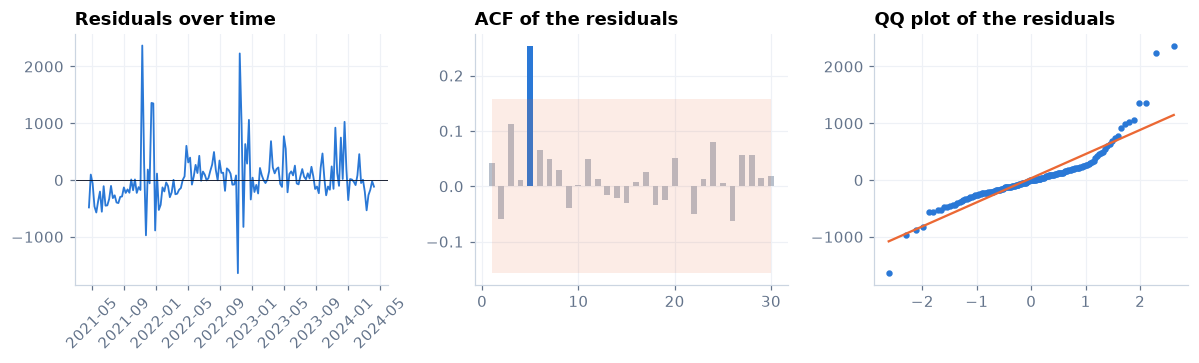

In [32]:
plots.residual_diagnostics(dates_h[burn:], resid_net, TS.acf_pacf(resid_net, 30))

The residual ACF stays almost entirely inside the band: the SARIMA has captured the dependence, with at most
a borderline Ljung-Box result at one lag. The QQ plot shows heavy tails (a few exceptional weeks), and
ARCH-LM detects **volatility clustering**: some periods are noisier than others. We model that variance
with GARCH(1, 1), then test the *standardised* residuals (residual ÷ its GARCH volatility) again:

omega      0.35
alpha[1]   0.18
beta[1]    0.45
Name: params, dtype: float64


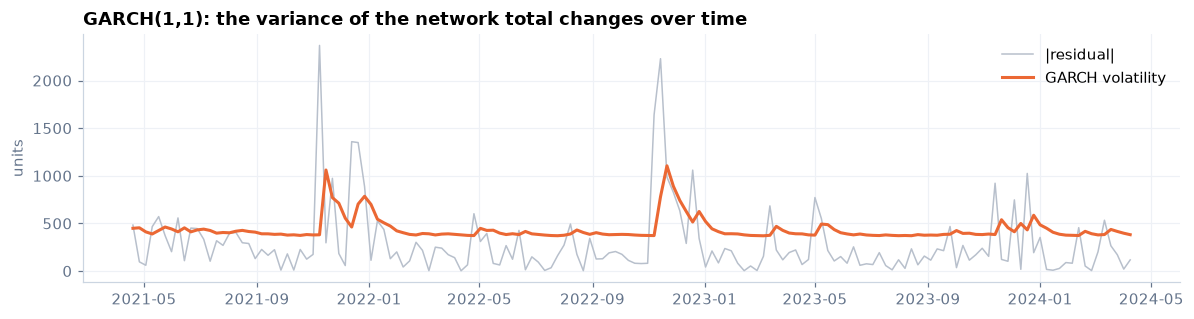

,SARIMA residuals,after GARCH,"after GARCH, squared"
Ljung-Box p (lag 4),0.09,0.50,0.95
Ljung-Box p (lag 8),0.01,0.05,0.75
Ljung-Box p (lag 13),0.12,0.25,0.94
Ljung-Box p (lag 26),0.70,0.74,1.00
Jarque-Bera p,0.00,0.00,0.00
ARCH-LM p,0.03,0.96,1.00
white noise,False,True,True
ARCH effect,True,False,False


In [33]:
garch_net, gscale = TS.fit_garch(resid_net)                # GARCH(1,1) on the residuals
print(garch_net.params.round(3))
std_net = np.asarray(garch_net.std_resid)                  # residual / its GARCH volatility
gtests = pd.DataFrame({"SARIMA residuals": rt_net, "after GARCH": TS.residual_tests(std_net),
                       "after GARCH, squared": TS.residual_tests(std_net ** 2)})
plots.garch_volatility(dates_h[burn:], resid_net, np.asarray(garch_net.conditional_volatility) * gscale)
gtests

After GARCH, the standardised residuals and their squares pass Ljung-Box and ARCH-LM: **no autocorrelation
and no volatility clustering are left**. Normality (Jarque-Bera) is still rejected because of a few extreme
weeks. This does not bias the forecast; it only means normal-based intervals would be too narrow in those
weeks (the stock policy uses a count distribution instead, step 14).

### 11.2 Does the forecast hold up on unseen weeks?

Fitted on the history only, the network model forecasts the 8 competition weeks, with 80% and 95% intervals:

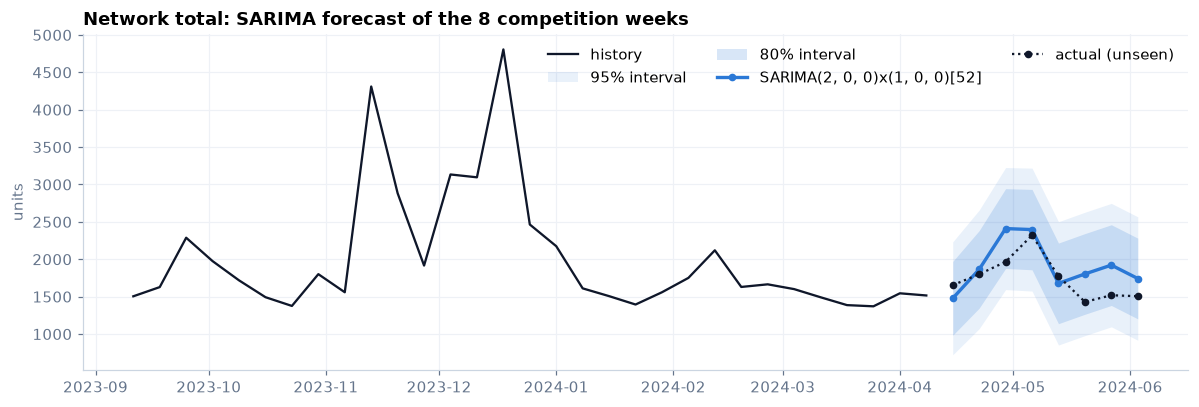

Error (MAPE): SARIMA 14.2% · same week last year 20.0%
Real weeks inside the 80% range: 100%


In [34]:
fc_net = fit_net.get_forecast(8)                           # fitted on history only, forecasts weeks 1-8
mean_net = np.asarray(fc_net.predicted_mean)
ci80, ci95 = np.asarray(fc_net.conf_int(alpha=.2)), np.asarray(fc_net.conf_int(alpha=.05))
actual_net = panel.sales.iloc[:, t0 + 1:t0 + 9].sum(axis=0).to_numpy()
last_year = total.iloc[t0 + 1 - 52:t0 + 9 - 52].to_numpy()                 # "same week last year"
fc_dates = panel.dates[t0 + 1:t0 + 9]
plots.holdout_forecast(total.iloc[t0 - 30:t0 + 1], fc_dates, mean_net, ci80, ci95, actual_net, best_net["model"])

mape = lambda f: np.mean(np.abs(f - actual_net) / actual_net) * 100
inside80 = np.mean((actual_net >= ci80[:, 0]) & (actual_net <= ci80[:, 1]))
print(f"Error (MAPE): SARIMA {mape(mean_net):.1f}% · same week last year {mape(last_year):.1f}%")
print(f"Real weeks inside the 80% range: {inside80:.0%}")

### 11.3 Every store-product

The same tests on the residuals of the 599 automatically selected ARIMA models (Ljung-Box at lags 4, 8 and
13; ARCH-LM at lag 4). With a 5% test level, about 5% of perfectly good models fail by chance alone. Where
ARCH-LM finds volatility clustering, a GARCH(1, 1) is fitted and the test repeated.

White-noise residuals: 91% · ARCH effect: 10%


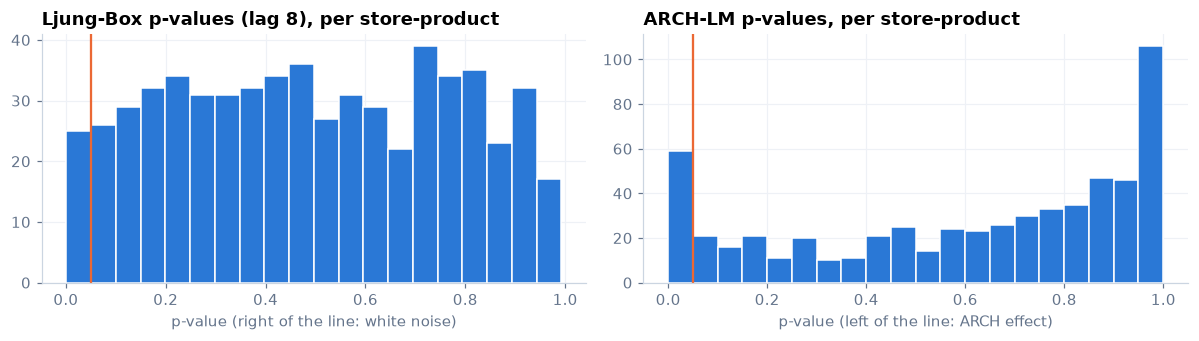

GARCH(1,1) on the 59 store-products with an ARCH effect: clustering removed in 85% of them


In [35]:
fitted = arima_tab.dropna(subset=["aic"])
wn = fitted["white noise"].astype(bool).mean()             # share passing Ljung-Box
arch_share = fitted["ARCH effect"].astype(bool).mean()     # share with volatility clustering
print(f"White-noise residuals: {wn:.0%} · ARCH effect: {arch_share:.0%}")
plots.pvalue_histograms(fitted["Ljung-Box p (lag 8)"], fitted["ARCH-LM p"])

season_h = M.season_of(M.season_factors(hist.upto(t0)), dates_h)
g_rows = TS.garch_on_arch_rows(arima_tab, demand.loc[:, hist_cols], season_h)
print(f"GARCH(1,1) on the {len(g_rows)} store-products with an ARCH effect: "
      f"clustering removed in {1 - g_rows['ARCH left after GARCH'].mean():.0%} of them")

**Steps 4-11 in short.** The classical workflow works on these series: most are stationary without
differencing, the network total is a seasonal AR process (SARIMA), and the residuals of the selected models
are white noise for the large majority of store-products. Volatility clustering exists for a minority, and
GARCH(1, 1) removes it. The ARIMA family now joins the forecasting race in step 12, where it is judged on
the same unseen weeks as every other method.

## 12 · Forecasting models

Each model sees the history up to the forecast origin and predicts the next three weeks. Why three?
An order placed before week *k* arrives in week *k+2*, so the planner needs weeks *k*, *k+1* (to project
the stock left when the order lands) and *k+2* (the week the order must cover).

| Model | Family | Idea |
|---|---|---|
| Last week | baseline | next weeks = the last clean week |
| 13-week average | baseline | mean of the last 13 clean weeks |
| Same week last year | baseline | the week 52 weeks before the target |
| Seasonal average (benchmark) | statistical | the **official VN2 benchmark**: 13-week mean of deseasonalised sales × seasonal factor |
| Exponential smoothing | statistical | weighted average with weights fading geometrically; smoothing α picked per row |
| ARIMA (AIC-selected) | statistical | the Box-Jenkins model of steps 4-11, one per store-product: d by ADF, p and q by AIC |
| Croston SBA | intermittent | smooths sale size and gap between sales separately; bias-corrected |
| TSB | intermittent | smooths sale size and *probability* of a sale; fades out dying products |
| LightGBM | machine learning | one gradient-boosted tree model for all 599 rows; features below |
| Ensemble | combination | mean of LightGBM, exponential smoothing and seasonal average |

Each model is a short function in `src/optichain/models.py`. Croston, for example, keeps just two smoothed
numbers per store-product: the size of a sale and the gap between sales.

**LightGBM features** (all computed from data available at the origin):

* clean demand of the last 8 weeks, raw sales and in-stock flags of the last 4 weeks;
* rolling means over 4, 8, 26 and 52 weeks, 13-week standard deviation, share of zero weeks, in-stock share;
* the same week last year and two years ago, the seasonal factor of the target week, ISO week number, horizon;
* weeks since launch, the row's level (log), and the hierarchy codes (store, product, product group,
  division, department, department group, store format) as categorical features.

All demand features are divided by the row's recent level, so one model fits slow and fast sellers.
The loss is **Tweedie**, designed for non-negative data with many zeros (it beat squared error, absolute
error and Huber in a quick test on past weeks). Out-of-stock weeks are never used as training targets.

Let us look at every model's forecast for one row at week 0:

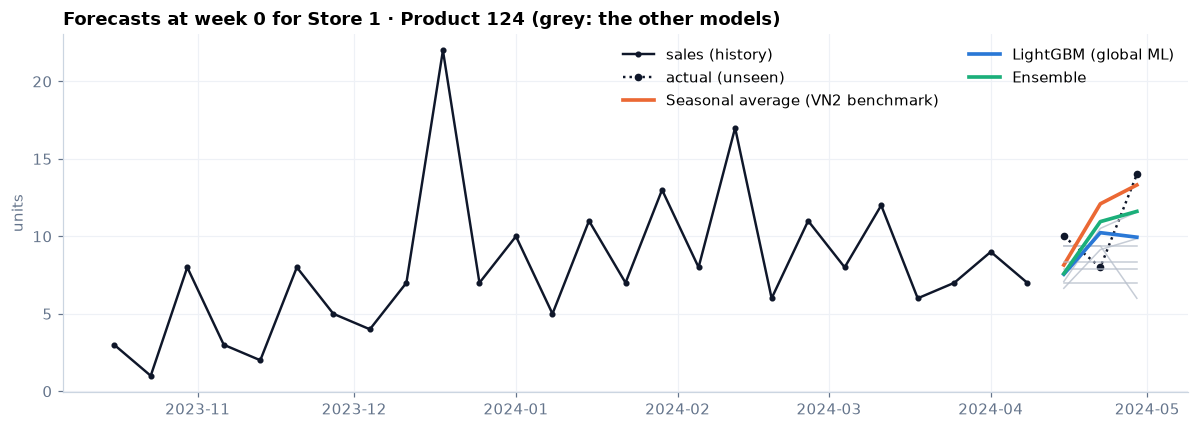

In [36]:
lgbm_demo = M.GlobalLGBM(3, seed=SEED).fit(hist.upto(t0))  # one model trained on all store-products
demo = M.forecast_all(hist.upto(t0), 3, cfg.forecast.models, lgbm_demo, cfg.forecast.ensemble_of, arima_rows)
row = panel.index.get_loc(example)                         # the store-product shown in step 3
plots.model_forecasts(panel.sales.iloc[row, t0 - 25:t0 + 1], panel.sales.iloc[row, t0 + 1:t0 + 4],
                      {m: f[row] for m, f in demo.items()}, M.MODEL_LABELS,
                      f"Forecasts at week 0 for Store {example[0]} · Product {example[1]}")

## 13 · Backtest: which model forecasts best?

At each of 30 past weeks (the *origins*) every model forecasts the next 3 weeks using only data up to
that origin. LightGBM is refitted every 4 origins and the ARIMA orders are re-selected every 8.
Errors are scored only on clean weeks.

**Metrics** (lower is better):
* **MAE**: mean absolute error, in units per row-week.
* **Bias %**: total over-forecast as a % of demand (+ = too high).
* **WAPE %**: sum of absolute errors / sum of demand.
* **Score %** = WAPE + |Bias|: the metric of the VN1 forecasting competition; it punishes both noise and
  systematic over- or under-forecasting.

This is the slowest cell (about 8 minutes).

In [37]:
# At each of the 30 dates, every model forecasts 3 weeks using only earlier data (about 6 minutes)
bt, bt_info = E.backtest(hist, origins, cfg.forecast.models, cfg.forecast.horizon, cfg.forecast.ensemble_of,
                         cfg.forecast.lgbm_retrain_every, SEED, arima_refit_every=cfg.forecast.arima_refit_every)
lb = E.leaderboard(bt)                                     # MAE, RMSE, Bias, WAPE and Score per model
lb.insert(1, "label", lb["model"].map(M.MODEL_LABELS))
lb

,model,label,MAE,RMSE,Bias %,WAPE %,Score %,Weeks scored
0,lightgbm,LightGBM (global ML),1.89,6.29,-1.87,55.20,57.08,"53,246.00"
1,ensemble,Ensemble,1.96,6.45,2.43,57.17,59.60,"53,246.00"
2,seasonal_ma,Seasonal average (VN2 benchmark),2.06,6.85,3.54,60.11,63.65,"53,246.00"
3,tsb,TSB,2.17,8.18,0.90,63.43,64.33,"53,246.00"
4,arima,ARIMA (AIC-selected),2.07,6.81,4.61,60.38,64.99,"53,246.00"
5,croston_sba,Croston SBA,2.15,8.19,-2.88,62.73,65.61,"53,246.00"
6,ses,Exponential smoothing,2.07,7.04,5.63,60.42,66.05,"53,246.00"
7,ma13,13-week average,2.27,8.48,3.23,66.20,69.42,"53,246.00"
8,snaive,Same week last year,2.41,7.11,-0.50,70.34,70.84,"53,246.00"
9,naive,Last week,2.55,9.62,0.99,74.58,75.57,"53,246.00"


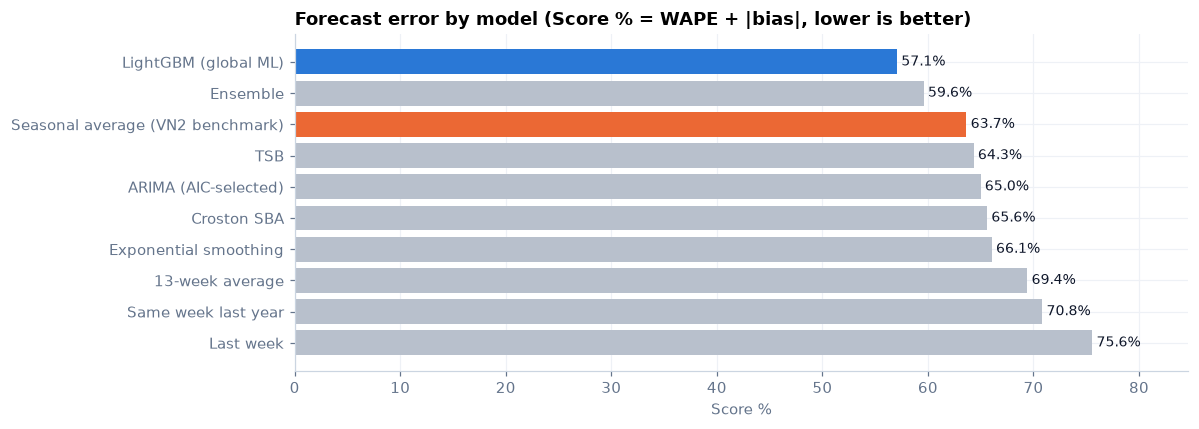

Most accurate: LightGBM (global ML) (57.1%) · benchmark forecast 63.7%


In [38]:
plots.leaderboard(lb)
best_fc = lb.iloc[0]["model"]
bench_score = lb.set_index("model").loc["seasonal_ma", "Score %"]
print(f"Most accurate: {M.MODEL_LABELS[best_fc]} ({lb.iloc[0]['Score %']:.1f}%) · benchmark forecast {bench_score:.1f}%")

By forecast horizon and by demand pattern:

In [39]:
lb_h = E.leaderboard(bt, ["h"])                            # by weeks ahead
display(lb_h.pivot(index="model", columns="h", values="Score %").round(1))
bt_pat = bt.merge(classes[["pattern"]].reset_index(drop=True).rename_axis("row").reset_index(), on="row")
lb_p = E.leaderboard(bt_pat, ["pattern"])                  # by demand pattern
lb_p.pivot(index="model", columns="pattern", values="Score %").round(1)

h,1,2,3
model,,,
arima,64.40,65.40,65.20
croston_sba,64.70,65.80,66.40
ensemble,58.90,59.70,60.30
lightgbm,55.20,57.30,58.80
ma13,67.60,69.80,70.90
naive,70.30,76.40,80.00
seasonal_ma,63.00,63.80,64.10
ses,64.50,66.70,66.90
snaive,70.90,70.90,70.70


pattern,erratic,intermittent,lumpy,smooth
model,,,,
arima,62.90,127.40,114.00,44.90
croston_sba,70.10,111.10,108.70,44.70
ensemble,56.20,109.70,103.90,38.10
lightgbm,62.90,104.60,96.10,34.80
ma13,66.10,112.80,119.40,43.30
naive,67.90,118.10,126.60,52.30
seasonal_ma,56.70,113.50,109.40,41.90
ses,56.80,114.70,113.00,43.20
snaive,92.20,148.80,136.90,40.90


Reading the tables: forecasting gets slightly harder further ahead, and much harder for intermittent and
lumpy rows (where a 100% error is common: forecasting 1 unit and selling 0 or 2). The ranking of the
models is stable across horizons.

**What drives LightGBM?** Feature importance (share of total gain) from the last fitted model:

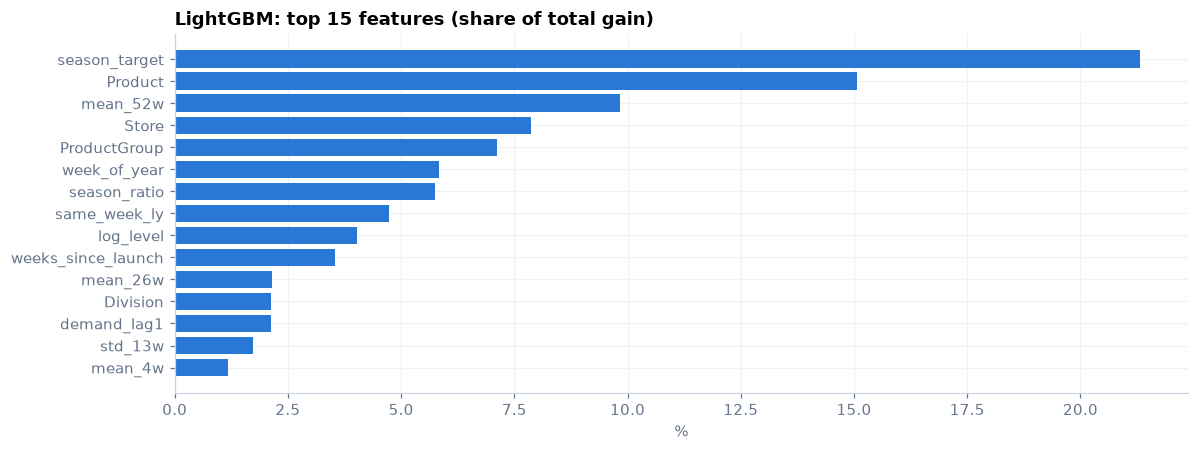

In [40]:
imp = bt_info["lgbm"].importance()                         # share of total gain per feature
plots.importance(imp)

Recent levels (rolling means, recent lags) dominate, as expected. Seasonal features and the hierarchy
add the rest: they let the model share patterns across similar rows.

### 13.1 Are the forecast errors white noise? Ljung-Box on the backtest

Step 11 tested in-sample residuals. The stricter check uses **real forecast errors**: for every
store-product, the sequence of its 1-week-ahead errors over the 30 backtest weeks is tested with Ljung-Box
(lag 4). If a method leaves a pattern in its errors (for example, it is always late to follow a change),
the test rejects. With a 5% test, about 95% of store-products should pass for an ideal method.

In [41]:
whiteness = TS.error_whiteness(bt, cfg.forecast.models, lag=4)   # Ljung-Box on each store-product's errors
whiteness.round(2)

,rows_tested,white_noise_share,median_p
model,,,
ses,599,0.93,0.44
ensemble,599,0.93,0.46
lightgbm,599,0.92,0.45
tsb,599,0.92,0.46
croston_sba,599,0.91,0.42
snaive,599,0.90,0.44
seasonal_ma,599,0.90,0.43
arima,599,0.89,0.40
ma13,599,0.88,0.39


Most methods leave white-noise errors for the large majority of store-products: what they miss is mostly
unpredictable noise, not a pattern they failed to learn. A Ljung-Box pass does not prove a forecast is
*right* (a constant forecast of the mean can pass too); it shows no exploitable pattern is left. Accuracy
(the leaderboard) and whiteness together are the evidence.

## 14 · Uncertainty: how wrong can a forecast be?

An order must cover more than the average week. We need the *spread* of demand around each forecast.
Weekly unit counts are well described by a **negative binomial** distribution with mean μ (the forecast)
and variance k·μ. k = 1 is pure Poisson noise; larger k means spikier demand.

We estimate k per row and model from backtest errors: k = Σ error² / Σ forecast, shrunk towards the
model's pooled value because each row has few clean weeks. To keep the test honest, the k used for the
policy tuning comes only from origins 1-12; the later origins check whether the resulting quantiles are
*calibrated*: the 80% quantile should be above demand about 80% of the time.

In [42]:
disp_early = E.dispersion(bt[bt.origin.isin(disp_origins)], hist.n)   # spread k from dates 1-12 (for tuning)
disp_all = E.dispersion(bt, hist.n)                                   # spread k from all 30 dates (for the test)
calib = E.calibration(bt[bt.origin.isin(tune_origins)], disp_early, M.MODEL_LABELS)
calib.round(2)

,pooled k,demand ≤ q50,demand ≤ q80,demand ≤ q95
model,,,,
ARIMA (AIC-selected),17.70,0.51,0.86,0.98
Croston SBA,29.13,0.46,0.83,0.98
Ensemble,15.92,0.51,0.86,0.99
LightGBM (global ML),15.14,0.51,0.85,0.98
13-week average,27.92,0.50,0.83,0.98
Last week,36.80,0.48,0.71,0.81
Seasonal average (VN2 benchmark),16.78,0.50,0.83,0.98
Exponential smoothing,17.28,0.51,0.85,0.98
Same week last year,12.96,0.55,0.76,0.83


The quantiles are not perfectly calibrated: the spread is estimated mostly from large, volatile rows, so
upper quantiles tend to be generous. This is fine, because the ordering policy will not take the 83.3%
quantile on faith: step 16 tunes the service level **by simulating real costs**, which corrects any
miscalibration (the approach every top-20 VN2 participant used).

## 15 · The inventory simulator (official rules)

The competition played every order with this arithmetic, once per week, for every store-product:

```
stock at start = stock left last week + the order arriving this week
sales          = min(stock at start, demand)
missed sales   = demand - sales                (lost: no back-orders)
stock left     = stock at start - sales
cost           = 0.20 x stock left + 1.00 x missed sales
```

Before trusting it, we reproduce the official result: the organiser published the six benchmark order
files and its score, **913.8 € setup + 4,334.0 €**. We check both the published orders and our own
re-implementation of the benchmark policy (seasonal average, order up to 4 weeks of forecast).

In [43]:
costs = I.Costs(cfg.competition.holding_cost, cfg.competition.shortage_cost)   # €0.20 and €1
initial = I.State.from_initial(panel.initial)                                 # the real starting stock
comp_demand = panel.sales.iloc[:, t0 + 1:t0 + 9].to_numpy()                   # demand of weeks 1-8

# 1. The organiser's published benchmark orders
bench_orders = [o.to_numpy() for o in D.load_benchmark_orders(cfg.paths.raw_dir)]
bench_weekly, _, _ = I.simulate(initial, comp_demand, bench_orders, costs)
setup = round(bench_weekly.loc[1:2, "cost"].sum(), 1)
bench_official = round(bench_weekly.loc[3:8, "cost"].sum(), 1)

# 2. Our own re-implementation of the benchmark policy
bench_fc = [M.seasonal_ma(hist.upto(t0 + r), 4) for r in range(6)]
_, _, our_orders, _ = I.replay(initial, comp_demand, bench_fc, None, costs, policy="order_up_to", coverage=4, n_orders=6)
same = all((a == b).all() for a, b in zip(our_orders, bench_orders))

assert bench_official == cfg.competition.benchmark_score and same
print(f"Setup €{setup:,.1f} · score €{bench_official:,.1f} · identical orders: {same}  ✓ simulator verified")
bench_weekly.round(1)

Setup €913.8 · score €4,334.0 · identical orders: True  ✓ simulator verified


,start,sales,lost,end,orders,holding,shortage,cost
week,,,,,,,,
1,"2,225.00","1,432.00",222.00,793.00,"3,987.00",158.60,222.00,380.60
2,"2,492.00","1,471.00",329.00,"1,021.00","1,657.00",204.20,329.00,533.20
3,"5,008.00","1,819.00",147.00,"3,189.00","1,043.00",637.80,147.00,784.80
4,"4,846.00","1,979.00",342.00,"2,867.00","1,359.00",573.40,342.00,915.40
5,"3,910.00","1,519.00",255.00,"2,391.00","1,401.00",478.20,255.00,733.20
6,"3,750.00","1,314.00",116.00,"2,436.00","1,932.00",487.20,116.00,603.20
7,"3,837.00","1,402.00",117.00,"2,435.00",0.00,487.00,117.00,604.00
8,"4,367.00","1,405.00",101.00,"2,962.00",0.00,592.40,101.00,693.40


The simulator matches the organiser's result to the cent, and our benchmark places exactly the same
orders. Every score below is therefore directly comparable with the official leaderboard.

## 16 · The ordering policy

**Idea.** Before week *k* we order *Q* units that land in week *k+2*. When they land, the shelf holds
whatever is left after weeks *k* and *k+1*. So:

1. Draw 1,000 demand paths for weeks *k, k+1, k+2* from the negative binomial (forecast μ, spread k).
2. Play weeks *k* and *k+1* on each path with the stock and orders already on their way, with lost
   sales: this gives the stock **X** left when the order lands (a distribution, not a number).
3. The order must cover **Y = demand(k+2) − X**. With cost *h* per unit left and *p* per unit short,
   the best *Q* is the **service-level quantile** of *Y*: the classic newsvendor solution, with the
   textbook level p / (p + h) = 1 / 1.2 = **0.833**.

The code is `newsvendor_orders` in `src/optichain/inventory.py`.

**Tuning by simulation.** The textbook 0.833 assumes a perfect demand distribution. Instead, we replay
18 past weeks (origins 13-30) for every model and a grid of service levels, using the backtest forecasts
and the spread from origins 1-12, and keep the level with the lowest total cost. The first 3 weeks of
each replay are warm-up (they depend on the arbitrary starting stock) and are not scored. All service
levels share the same random demand paths, so differences come from the policy alone.

For comparison we also replay the benchmark's *order-up-to-N-weeks* rule with N = 2.5 to 4.

In [44]:
grid = cfg.policy.service_grid
tuning = P.tune_service_levels(bt, tune_origins, hist.sales, disp_early, costs, cfg.forecast.models, grid,
                               samples=cfg.policy.samples, seed=SEED, warmup=cfg.policy.replay_warmup)
best_service = P.best_settings(tuning, "newsvendor")       # cheapest service level per model
best_cov = P.best_settings(tuning, "order_up_to")          # cheapest coverage per model (benchmark-style rule)
best_service.sort_values("cost")

,policy,param,cost
model,,,
ensemble,newsvendor,0.75,"11,435.40"
lightgbm,newsvendor,0.75,"11,466.60"
ses,newsvendor,0.75,"12,158.00"
seasonal_ma,newsvendor,0.75,"12,195.20"
arima,newsvendor,0.75,"12,343.00"
croston_sba,newsvendor,0.75,"13,360.60"
tsb,newsvendor,0.70,"13,496.00"
ma13,newsvendor,0.70,"14,534.40"
snaive,newsvendor,0.60,"15,895.40"


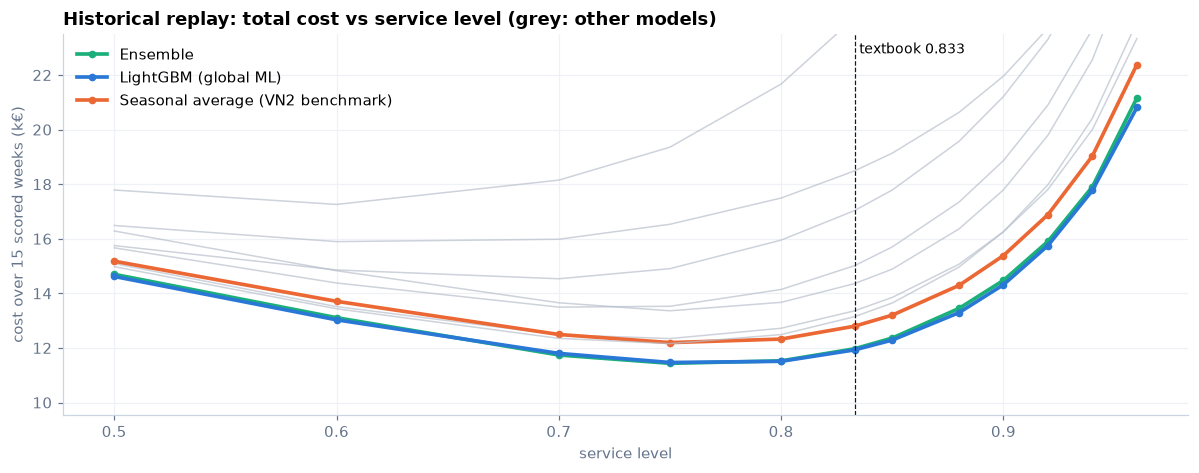

Chosen plan: Ensemble at service level 0.75


In [45]:
plots.tuning_curves(tuning[tuning.policy == "newsvendor"], M.MODEL_LABELS, costs.critical_ratio)
plan_model = best_service["cost"].idxmin()                 # the model with the cheapest replay
plan_service = float(best_service.loc[plan_model, "param"])
print(f"Chosen plan: {M.MODEL_LABELS[plan_model]} at service level {plan_service}")

Two lessons. First, a better forecast directly lowers cost: the curves are ordered almost exactly like
the accuracy leaderboard. Second, the best service level sits *below* the textbook 0.833, because the
estimated spread is generous (step 14) and leftover stock is not wasted: it sells next week. Tuning by
simulation absorbs both effects.

## 17 · Final test: the eight VN2 weeks

Now the real test, played exactly like the competition. Before each round *r* the models are refitted on
the data available then (sales and in-stock flags up to week *r−1*) and forecast 4 weeks ahead. Each
model plays with **the service level chosen on the past** in step 16; nothing here is tuned on the
competition weeks. We also compute rounds 7-9 (the plan continuing after VN2's last order) for the
outlook in step 18.

In [46]:
# Forecasts of every round, refitting on the data known then (about 6 minutes)
rounds = P.round_forecasts(hist, t0, cfg.forecast.models, cfg.forecast.ensemble_of, n_rounds=9, horizon=4, seed=SEED)

# Accuracy on the competition weeks (1 to 3 weeks ahead, clean weeks only)
acc = rounds[(rounds.h <= 3) & (rounds.week <= 8)].copy()
acc["demand"] = demand.to_numpy()[acc["row"], t0 + acc["week"]]
lb_comp = E.leaderboard(acc)
lb_comp.insert(1, "label", lb_comp["model"].map(M.MODEL_LABELS))
lb_comp[["label", "MAE", "Bias %", "WAPE %", "Score %"]].round(2)

,label,MAE,Bias %,WAPE %,Score %
0,Seasonal average (VN2 benchmark),1.60,2.05,54.62,56.67
1,Ensemble,1.58,4.52,54.08,58.60
2,Croston SBA,1.67,2.01,57.23,59.25
3,TSB,1.65,3.86,56.45,60.30
4,13-week average,1.60,-6.18,54.65,60.83
5,LightGBM (global ML),1.58,6.77,54.16,60.93
6,Exponential smoothing,1.64,4.73,56.21,60.94
7,ARIMA (AIC-selected),1.67,5.78,57.09,62.87
8,Last week,1.99,1.82,68.03,69.85
9,Same week last year,2.36,19.74,80.53,100.27


**An honest surprise.** On these eight weeks, the simple seasonal average (the benchmark's forecast) has the
lowest error, ahead of the ensemble, while LightGBM, best over the 30 backtest weeks, slips down the table.
Eight weeks is a short window (against 30 forecast dates in the backtest), so rankings
move. What matters for the planner is the next table: the cost of the orders each forecast leads to.

In [47]:
comp_scores, comp_grid = P.score_competition(initial, comp_demand, rounds, disp_all, costs, cfg.forecast.models,
                                             M.MODEL_LABELS, best_service, best_cov, grid, cfg.policy.samples, SEED)
comp_scores

,model,label,service (tuned on past),VN2 score €,order-up-to score €,hindsight best €,hindsight service
0,ensemble,Ensemble,0.75,"3,626.40","3,798.40","3,626.40",0.75
1,lightgbm,LightGBM (global ML),0.75,"3,680.20","3,802.20","3,680.20",0.75
2,seasonal_ma,Seasonal average (VN2 benchmark),0.75,"3,750.80","3,901.00","3,736.80",0.80
3,arima,ARIMA (AIC-selected),0.75,"3,756.80","3,993.80","3,756.80",0.75
4,ses,Exponential smoothing,0.75,"3,817.00","4,107.00","3,817.00",0.75
5,croston_sba,Croston SBA,0.75,"3,976.80","4,041.00","3,905.00",0.80
6,tsb,TSB,0.70,"4,009.20","4,433.00","3,836.20",0.80
7,ma13,13-week average,0.70,"4,277.20","4,805.40","3,910.40",0.83
8,naive,Last week,0.60,"5,218.40","6,039.60","5,059.40",0.70
9,snaive,Same week last year,0.60,"5,468.40","5,458.60","5,468.40",0.60


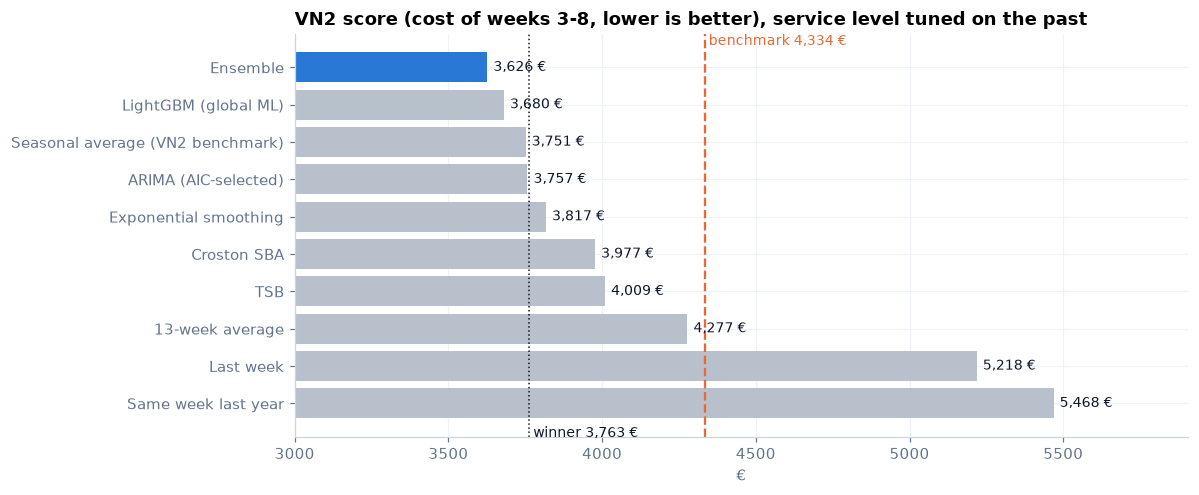

Plan: Ensemble @ 0.75 → €3,626.4 (16.3% below the benchmark)


In [48]:
plan_score = float(comp_scores.set_index("model").loc[plan_model, "VN2 score €"])
plots.competition_scores(comp_scores, plan_model, cfg.competition.benchmark_score, cfg.competition.winner_score)
print(f"Plan: {M.MODEL_LABELS[plan_model]} @ {plan_service} → €{plan_score:,.1f} "
      f"({1 - plan_score / bench_official:.1%} below the benchmark)")

**How to read this honestly.** Each policy used only information available at the time, and its
service level was chosen on past weeks. The score is computed with the organiser's rules and the same
starting stock. But this was built *after* the competition: we knew which kinds of methods did well
(global gradient boosting, simulation-tuned policies), so a "would have ranked" comparison carries some
hindsight. The fair claim is that the pipeline clearly beats the benchmark and performs in the range of
the top entries. The *hindsight best* column shows the score with the best service level chosen on the
competition weeks themselves: the gap to the tuned score is small, so the tuning on the past transfers.

Weekly cost of the chosen plan against the benchmark:

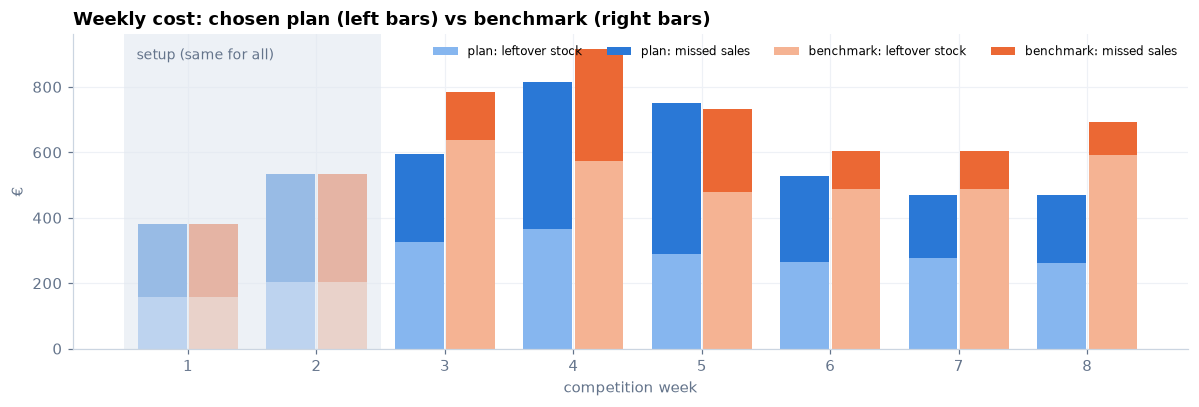

,plan cost,benchmark cost
week,,
1,380.60,380.60
2,533.20,533.20
3,596.40,784.80
4,814.80,915.40
5,749.60,733.20
6,527.00,603.20
7,468.80,604.00
8,469.80,693.40


In [49]:
plan = P.run_plan(initial, comp_demand, rounds, P.k_vector(disp_all, plan_model), plan_model, plan_service, costs,
                  cfg.policy.samples, SEED)
plots.weekly_costs(plan.weekly, bench_weekly)
pd.DataFrame({"plan cost": plan.weekly["cost"], "benchmark cost": bench_weekly["cost"]}).round(1)

## 18 · Stock outlook: the next order

The data ends on 3 June 2024 (week 8). If the plan had kept ordering in rounds 7 and 8, what should the
planner order now (arriving in week 11), and which rows are at risk of running out in weeks 9-11?
The risk comes from the same 1,000 demand paths: the share of paths in which the shelf runs empty.

In [50]:
out = P.outlook_table(panel.index, classes["pattern"].to_numpy(), plan, P.forecast_matrix(rounds, plan_model, 9))
print(f"Order now: {out['order now'].sum():,.0f} units for {(out['order now'] > 0).sum()} store-products")
print(f"High risk (>50%) of an empty shelf next week: {(out['risk wk 9'] > .5).sum()} store-products")
out.sort_values("risk wk 9", ascending=False).head(10).round(2)

Order now: 1,162 units for 271 store-products
High risk (>50%) of an empty shelf next week: 19 store-products


,store,product,pattern,on shelf,arriving wk 9,arriving wk 10,forecast wk 9-11,order now,risk wk 9,risk wk 10,risk wk 11
17,12,124,erratic,0.00,5.00,6.00,27.71,11,0.85,0.59,0.21
61,43,17,smooth,0.00,3.00,7.00,15.98,5,0.70,0.19,0.19
64,45,17,erratic,0.00,12.00,12.00,42.04,15,0.68,0.44,0.23
447,62,102,intermittent,0.00,0.00,1.00,4.05,1,0.65,0.34,0.22
472,62,159,smooth,0.00,1.00,2.00,6.55,2,0.62,0.26,0.22
68,48,126,lumpy,0.00,0.00,0.00,5.93,3,0.61,0.57,0.16
70,49,103,lumpy,0.00,0.00,0.00,5.24,2,0.61,0.53,0.22
258,61,92,erratic,0.00,0.00,1.00,3.02,1,0.60,0.24,0.15
6,4,124,smooth,0.00,10.00,10.00,30.63,10,0.59,0.30,0.21
52,37,103,lumpy,0.00,1.00,0.00,12.43,6,0.57,0.64,0.22


Weeks 9 and 10 are already decided: only the stock on hand and in transit can serve them. The new order
controls week 11, which is why its risk is close to 1 − service level for most rows.

## 19 · Save the artefacts for the dashboard

In [51]:
# Tables
files = {"audit.csv": audit, "leaderboard.csv": lb, "leaderboard_h.csv": lb_h, "leaderboard_pattern.csv": lb_p,
         "leaderboard_competition.csv": lb_comp, "calibration.csv": calib, "competition_scores.csv": comp_scores,
         "benchmark_weekly.csv": bench_weekly, "outlook.csv": out, "error_whiteness.csv": whiteness,
         "tuning.csv": pd.concat([tuning, comp_grid]), "importance.csv": imp.rename("gain").rename_axis("feature"),
         "season.csv": season.rename("factor").rename_axis("iso_week")}
for name, table in files.items():
    table.to_csv(ART / name, index=name not in {"leaderboard.csv", "leaderboard_h.csv", "leaderboard_pattern.csv",
                                                "leaderboard_competition.csv", "competition_scores.csv", "outlook.csv", "tuning.csv"})
long.merge(classes["pattern"].reset_index(), on=D.INDEX).to_parquet(ART / "long.parquet")
classes.reset_index().to_parquet(ART / "classes.parquet")
bt.to_parquet(ART / "backtest.parquet")
disp_all.to_parquet(ART / "dispersion.parquet")
rounds.to_parquet(ART / "rounds.parquet")
arima_tab.assign(order=arima_tab["order"].astype(str)).to_parquet(ART / "arima_rows.parquet")

# The headline numbers
idx = panel.index
summary = {"plan_model": plan_model, "plan_service": plan_service, "plan_score": plan_score, "plan_setup": plan.setup,
           "best_forecast_model": best_fc, "benchmark_score": bench_official, "setup": setup,
           "winner_score": cfg.competition.winner_score,
           "ranking": [("1st place", 3763.2), ("2nd place", 3764.6), ("3rd place", 3791.6), ("4th place", 3794.4),
                       ("5th place", 3824.4), ("VN2 benchmark", cfg.competition.benchmark_score)],
           "best_service": best_service["param"].astype(float).to_dict(), "rows": hist.n,
           "stores": idx.get_level_values("Store").nunique(), "products": idx.get_level_values("Product").nunique(),
           "weeks": panel.sales.shape[1], "history_weeks": t0 + 1,
           "first_week": f"{panel.dates[0]:%Y-%m-%d}", "last_week": f"{panel.dates[-1]:%Y-%m-%d}"}
(ART / "summary.json").write_text(json.dumps(summary, indent=2, default=int))

# The time-series results (dashboard: Model check page)
ts_net = {"stationarity": tr_tab.reset_index().rename(columns={"index": "series"}).astype(str).to_dict("records"),
          "d": d_net, "strength": TS.json_safe(s_net), "identify": id_net, "best": best_net["model"],
          "best_bic": best_bic["model"], "aic": grid_all[["model", "family", "AIC", "BIC", "ΔAIC", "parameters"]].head(12).to_dict("records"),
          "resid_tests": TS.json_safe(rt_net), "garch_params": TS.json_safe(garch_net.params.to_dict()),
          "garch_tests": {c: TS.json_safe(gtests[c].to_dict()) for c in gtests},
          "holdout_mape": mape(mean_net), "holdout_mape_snaive": mape(last_year), "rows_white_noise": wn,
          "rows_arch": arch_share, "adf_rows_stationary": np.mean(adf_all < .05),
          "garch_rows_fixed": 1 - g_rows["ARCH left after GARCH"].mean(), "ts_row": ts_row}
(ART / "ts_network.json").write_text(json.dumps(ts_net, indent=2, default=float))
dec.rename_axis("date").reset_index().to_parquet(ART / "ts_decomposition.parquet")
pd.DataFrame({"date": dates_h[burn:], "resid": resid_net,
              "volatility": np.asarray(garch_net.conditional_volatility) * gscale}).to_parquet(ART / "ts_residuals.parquet")
pd.DataFrame({"date": fc_dates, "forecast": mean_net, "lo80": ci80[:, 0], "hi80": ci80[:, 1], "lo95": ci95[:, 0],
              "hi95": ci95[:, 1], "actual": actual_net}).to_parquet(ART / "ts_holdout.parquet")
print(f"Saved {len(list(ART.iterdir()))} files to {ART}")

Saved 24 files to C:\Users\sanya\OptiChain\artifacts


## 20 · Conclusions

In [52]:
print(f"Time series: the network total is stationary and seasonal (strength {s_net['seasonal strength']:.2f}); "
      f"best model {best_net['model']}; white noise after GARCH. Per store-product ARIMA: {wn:.0%} white noise.")
print(f"Forecasting: {M.MODEL_LABELS[best_fc]} is the most accurate in the backtest "
      f"({lb.iloc[0]['Score %']:.1f}% vs {bench_score:.1f}% for the benchmark forecast).")
print(f"Stock policy: Monte Carlo newsvendor, service level {plan_service} tuned on past weeks.")
print(f"Result: {M.MODEL_LABELS[plan_model]} plan €{plan_score:,.1f} vs official benchmark €{bench_official:,.1f} "
      f"({1 - plan_score / bench_official:.1%} lower); winner €{cfg.competition.winner_score:,.1f}.")

Time series: the network total is stationary and seasonal (strength 0.93); best model SARIMA(2, 0, 0)x(1, 0, 0)[52]; white noise after GARCH. Per store-product ARIMA: 91% white noise.
Forecasting: LightGBM (global ML) is the most accurate in the backtest (57.1% vs 63.7% for the benchmark forecast).
Stock policy: Monte Carlo newsvendor, service level 0.75 tuned on past weeks.
Result: Ensemble plan €3,626.4 vs official benchmark €4,334.0 (16.3% lower); winner €3,763.2.


**Limitations**

* Demand in the simulation is the recorded sales, so it is itself censored in weeks that ran out in reality
  (the competition used the same convention).
* Eight test weeks is a short window: a few large rows can move the score by tens of euros.
* The spread model (variance = k × mean) is simple; quantile LightGBM or conformal intervals could calibrate better.
* Hindsight: the design was informed by the published VN2 results (see step 17).

**Next steps:** quantile or distributional LightGBM, per-segment service levels, and a policy that looks
beyond the arrival week (multi-period optimisation or reinforcement learning, as the 2nd place did).

*Data: Vandeput, N. (2025). VN2 Inventory Planning Challenge. Organised by Nicolas Vandeput (SupChains).
Sponsored by Flieber, Daybreak and SupChains. CC BY 4.0.*